In [1]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.ticker as mticker
import numpy as np
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.mpl.ticker as cticker
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import pandas as pd

ERROR 1: PROJ: proj_create_from_database: Open of /global/home/users/toireasamarie/.conda/envs/regrid_env2/share/proj failed


In [2]:
file = '/global/scratch/users/toireasamarie/0.1x0.1_deg_gridded_datasets/final_datasets/a10_lowCF_scaled_grouped_2hour_pulses.parquet'
groups_df = pd.read_parquet(file, engine='pyarrow')

file ='/global/scratch/users/toireasamarie/0.1x0.1_deg_gridded_datasets/final_datasets/a10_lowCF_scaled_filtered_merged_with_incdec.parquet'
df = pd.read_parquet(file, engine='pyarrow')

In [3]:
df

,grid_lat,grid_lon,h_precip_mm,datetime,no2_mean,no2_std,no2_sem,snow_ice_fraction_mean,snow_ice_fraction_std,cv_no2,...,pct_sandy_clay,pct_sandy_clay_loam,pct_sandy_loam,pct_silt,pct_silt_loam,pct_silty_clay,pct_silty_clay_loam,state_name,pre_slope,sm_class
0,36.05,-91.15,NaN,2024-02-29 22:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.000000,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,NaN,None
1,36.05,-91.15,NaN,2024-02-29 23:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.000000,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,NaN,None
2,36.05,-91.15,NaN,2024-03-01 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.000000,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,NaN,None
3,36.05,-91.15,NaN,2024-03-01 01:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.000000,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,NaN,None
4,36.05,-91.15,NaN,2024-03-01 02:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.000000,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,NaN,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
33395116,48.95,-96.85,0.345,2024-07-31 19:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,1.515152,88.636364,0.0,0.000000,0.000000,0.000000,Minnesota,NaN,None
33395117,48.95,-96.85,0.050,2024-07-31 20:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,1.515152,88.636364,0.0,0.000000,0.000000,0.000000,Minnesota,NaN,None
33395118,48.95,-96.85,0.000,2024-07-31 21:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,1.515152,88.636364,0.0,0.000000,0.000000,0.000000,Minnesota,NaN,None
33395119,48.95,-96.85,0.000,2024-07-31 22:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,1.515152,88.636364,0.0,0.000000,0.000000,0.000000,Minnesota,NaN,None


In [4]:
df.columns

Index(['grid_lat', 'grid_lon', 'h_precip_mm', 'datetime', 'no2_mean',
       'no2_std', 'no2_sem', 'snow_ice_fraction_mean', 'snow_ice_fraction_std',
       'cv_no2', 'datetime_local', 'local_hour', 'no2_scaled_by_hour',
       'pulse_start', 'sm_surface', 'surface_temp', 'soil_temp_layer1',
       'WFPS_c', 'dominant_texture', 'pct_clay', 'pct_clay_loam', 'pct_loam',
       'pct_loamy_sand', 'pct_sand', 'pct_sandy_clay', 'pct_sandy_clay_loam',
       'pct_sandy_loam', 'pct_silt', 'pct_silt_loam', 'pct_silty_clay',
       'pct_silty_clay_loam', 'state_name', 'pre_slope', 'sm_class'],
      dtype='object')

In [5]:
groups_df

,grid_lat,grid_lon,h_precip_mm,datetime,no2_mean,no2_std,no2_sem,snow_ice_fraction_mean,snow_ice_fraction_std,cv_no2,...,pct_sandy_loam,pct_silt,pct_silt_loam,pct_silty_clay,pct_silty_clay_loam,state_name,pre_slope,sm_class,time_num,group_id
0,37.35,-100.85,0.000,2024-03-13 16:00:00,2.173031e+15,6.369229e+14,1.273846e+14,0.0,0.0,0.293103,...,0.000000,0.0,75.000000,0.000000,22.727273,Kansas,-0.000005,decreasing,0.0,0
1,39.35,-92.75,0.000,2024-03-16 15:00:00,4.694567e+15,8.246832e+14,1.649366e+14,0.0,0.0,0.175668,...,0.000000,0.0,77.272727,0.000000,20.454545,Missouri,0.000689,increasing,71.0,1
2,39.15,-92.95,0.000,2024-03-16 15:00:00,2.622688e+15,1.454574e+15,2.969137e+14,0.0,0.0,0.554612,...,5.303030,0.0,71.969697,2.272727,11.363636,Missouri,0.000744,increasing,71.0,3
3,39.15,-92.85,0.000,2024-03-16 15:00:00,2.632403e+15,1.870482e+15,3.740963e+14,0.0,0.0,0.710561,...,1.388889,0.0,88.888889,0.694444,4.166667,Missouri,0.000872,increasing,71.0,3
4,39.15,-93.15,0.000,2024-03-16 15:00:00,2.643212e+15,1.089365e+15,2.178731e+14,0.0,0.0,0.412137,...,0.000000,0.0,100.000000,0.000000,0.000000,Missouri,0.000546,increasing,71.0,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2004,40.85,-95.05,0.000,2024-07-19 15:00:00,3.003975e+15,5.779969e+14,1.155994e+14,0.0,0.0,0.192411,...,0.000000,0.0,9.917355,0.000000,90.082645,Iowa,-0.000296,decreasing,3071.0,2004
2005,40.95,-94.75,0.000,2024-07-19 16:00:00,2.530260e+15,9.967452e+14,2.417462e+14,0.0,0.0,0.393930,...,0.000000,0.0,14.583333,0.000000,84.722222,Iowa,-0.000236,decreasing,3072.0,2005
2006,37.55,-98.35,0.105,2024-07-19 18:00:00,2.812737e+15,7.392236e+14,1.478447e+14,0.0,0.0,0.262813,...,45.454545,0.0,11.570248,0.000000,0.000000,Kansas,0.000606,increasing,3074.0,2006
2007,37.75,-98.65,0.000,2024-07-19 18:00:00,2.959582e+15,9.768195e+14,1.953639e+14,0.0,0.0,0.330053,...,81.818182,0.0,0.000000,0.000000,0.000000,Kansas,-0.000047,decreasing,3074.0,2007


In [6]:
groups_df.columns

Index(['grid_lat', 'grid_lon', 'h_precip_mm', 'datetime', 'no2_mean',
       'no2_std', 'no2_sem', 'snow_ice_fraction_mean', 'snow_ice_fraction_std',
       'cv_no2', 'datetime_local', 'local_hour', 'no2_scaled_by_hour',
       'pulse_start', 'sm_surface', 'surface_temp', 'soil_temp_layer1',
       'WFPS_c', 'dominant_texture', 'pct_clay', 'pct_clay_loam', 'pct_loam',
       'pct_loamy_sand', 'pct_sand', 'pct_sandy_clay', 'pct_sandy_clay_loam',
       'pct_sandy_loam', 'pct_silt', 'pct_silt_loam', 'pct_silty_clay',
       'pct_silty_clay_loam', 'state_name', 'pre_slope', 'sm_class',
       'time_num', 'group_id'],
      dtype='object')

In [7]:
import string

# sumary table to help pick events 
summary = (
    groups_df.groupby("group_id")
    .agg(
        sm_class=("sm_class", "first"),
        n_cells=("grid_lat", "nunique"),# spatial footprint size
        state=("state_name", "first"),
        t_start=("datetime", "min"),
        pre_slope=("pre_slope", "mean"),
        dominant_texture=("dominant_texture", "first"),
    )
    .reset_index()
)

print("=== Increasing events (sample) ===")
inc = summary[summary["sm_class"] == "increasing"].sort_values("n_cells", ascending=False)
print(inc[["group_id","n_cells","state","t_start","pre_slope","dominant_texture"]].head(30).to_string(index=False))

print("\n=== Decreasing events (sample) ===")
dec = summary[summary["sm_class"] == "decreasing"].sort_values("n_cells", ascending=False)
print(dec[["group_id","n_cells","state","t_start","pre_slope","dominant_texture"]].head(30).to_string(index=False))

print("\n--- Group size distribution ---")
print(summary.groupby("sm_class")["n_cells"].describe())

=== Increasing events (sample) ===
 group_id  n_cells        state             t_start  pre_slope dominant_texture
      733       15 South Dakota 2024-05-23 15:00:00   0.001627  silty clay loam
      877        9     Nebraska 2024-06-03 15:00:00   0.001086        clay loam
       76        8    Tennessee 2024-03-28 15:00:00   0.000727        silt loam
     1809        7     Nebraska 2024-07-09 15:00:00   0.000033  silty clay loam
      980        7         Iowa 2024-06-06 16:00:00  -0.000521  silty clay loam
     1348        7 South Dakota 2024-06-13 21:00:00   0.000270             loam
     1454        6 North Dakota 2024-06-19 15:00:00   0.000494             loam
      919        6     Nebraska 2024-06-02 20:00:00   0.000711  silty clay loam
     1654        5     Illinois 2024-07-07 15:00:00   0.000068        silt loam
     1997        5     Missouri 2024-07-18 15:00:00   0.000072             loam
      654        5 South Dakota 2024-05-23 15:00:00   0.001252             loam
     

/tmp/ipykernel_389250/1049949131.py:177: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0,0.02,1,0.99])


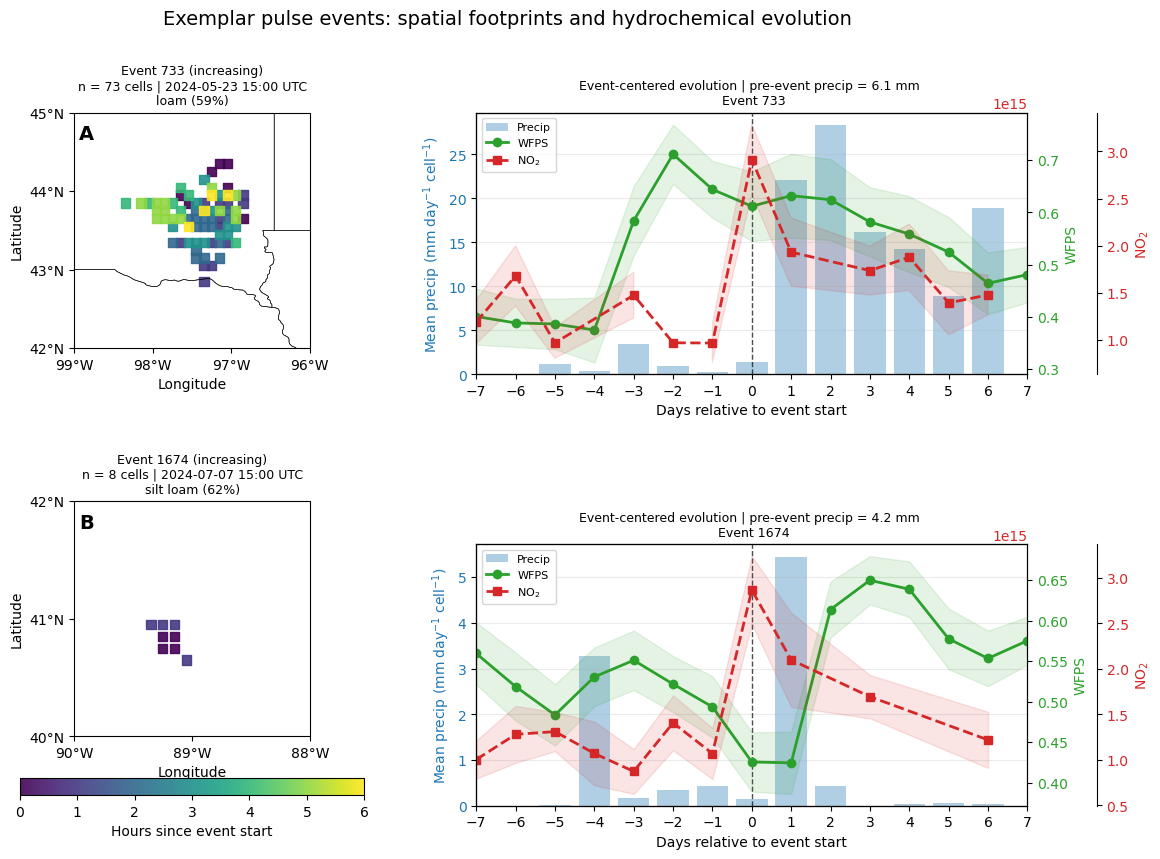

In [8]:

EXEMPLAR_EVENTS = [733,  1674]

pulse_df = groups_df.copy()
WINDOW_DAYS = 7

# --- validate ---
EXEMPLAR_EVENTS = [
    eid for eid in EXEMPLAR_EVENTS
    if eid is not None and eid in pulse_df["group_id"].unique()
]
assert len(EXEMPLAR_EVENTS) > 0, "Fill in at least one valid group_id above!"

n_events = len(EXEMPLAR_EVENTS)
panel_labels = list("ABCDEFGHIJKLMNOPQRSTUVWXYZ")

# global colour range
all_ep = pulse_df[pulse_df["group_id"].isin(EXEMPLAR_EVENTS)].copy()
all_ep["hours_since_start"] = (
    all_ep["datetime"]
    - all_ep.groupby("group_id")["datetime"].transform("min")
).dt.total_seconds() / 3600
vmin_time, vmax_time = 0, all_ep["hours_since_start"].max()

fig = plt.figure(figsize=(13, 4.5 * n_events))
outer = gridspec.GridSpec(n_events, 1, hspace=0.65)
map_axes, last_sc = [], None

for row, eid in enumerate(EXEMPLAR_EVENTS):
    inner = gridspec.GridSpecFromSubplotSpec(
        1, 2, subplot_spec=outer[row],
        width_ratios=[1.0, 1.6], wspace=0.25
    )

    event_pulses = pulse_df[pulse_df["group_id"] == eid].copy()
    event_cells  = event_pulses[["grid_lat", "grid_lon"]].drop_duplicates()
    if event_pulses.empty:
        continue

    t0 = event_pulses["datetime"].min()
    event_pulses["hours_since_start"] = (
        (event_pulses["datetime"] - t0).dt.total_seconds() / 3600
    )

    # soil texture label
    if "dominant_texture" in event_pulses.columns:
        es = (event_pulses[["grid_lat","grid_lon","dominant_texture"]]
              .drop_duplicates(subset=["grid_lat","grid_lon"])
              .dropna(subset=["dominant_texture"]))
        if len(es) > 0:
            sc_counts = es["dominant_texture"].value_counts()
            soil_str = f"{sc_counts.index[0]} ({sc_counts.iloc[0]/sc_counts.sum():.0%})"
        else:
            soil_str = "Soil texture unknown"
    else:
        soil_str = ""

    sm_label = event_pulses["sm_class"].iloc[0] if "sm_class" in event_pulses.columns else "Unknown"

    # ±7-day window from background df
    sub = df.merge(event_cells, on=["grid_lat","grid_lon"], how="inner").copy()
    sub = sub[
        (sub["datetime"] >= t0 - pd.Timedelta(days=WINDOW_DAYS)) &
        (sub["datetime"] <= t0 + pd.Timedelta(days=WINDOW_DAYS))
    ].copy()
    sub["lag_day"] = np.floor(
        (sub["datetime"] - t0).dt.total_seconds() / 86400.0
    ).astype(int)

    agg_cell = {"precip": ("h_precip_mm","sum"), "no2": ("no2_mean","mean")}
    if "WFPS_c" in sub.columns:
        agg_cell["wfps"] = ("WFPS_c","mean")
    cell_daily = sub.groupby(["grid_lat","grid_lon","lag_day"]).agg(**agg_cell).reset_index()

    agg_event = {
        "precip_mean": ("precip","mean"), "precip_std": ("precip","std"),
        "no2_mean":    ("no2","mean"),    "no2_std":    ("no2","std"),
    }
    if "wfps" in cell_daily.columns:
        agg_event["wfps_mean"] = ("wfps","mean")
        agg_event["wfps_std"]  = ("wfps","std")
    event_daily = cell_daily.groupby("lag_day").agg(**agg_event).reset_index()

    full_lags   = pd.DataFrame({"lag_day": np.arange(-WINDOW_DAYS, WINDOW_DAYS+1)})
    event_daily = full_lags.merge(event_daily, on="lag_day", how="left")
    event_daily[["precip_mean","precip_std"]] = event_daily[["precip_mean","precip_std"]].fillna(0)

    # ---- MAP ----
    ax_map = fig.add_subplot(inner[0], projection=ccrs.PlateCarree())
    map_axes.append(ax_map)
    lon_min = event_cells["grid_lon"].min()-0.5; lon_max = event_cells["grid_lon"].max()+0.5
    lat_min = event_cells["grid_lat"].min()-0.5; lat_max = event_cells["grid_lat"].max()+0.5
    ax_map.set_extent([lon_min,lon_max,lat_min,lat_max], crs=ccrs.PlateCarree())
    ax_map.add_feature(cfeature.STATES, linewidth=0.4)
    ax_map.add_feature(cfeature.BORDERS, linewidth=0.3)
    ax_map.coastlines(linewidth=0.3)
    sc = ax_map.scatter(
        event_pulses["grid_lon"], event_pulses["grid_lat"],
        c=event_pulses["hours_since_start"], cmap="viridis",
        vmin=vmin_time, vmax=vmax_time,
        s=45, marker="s", alpha=0.9, transform=ccrs.PlateCarree()
    )
    last_sc = sc
    ax_map.set_xticks(np.arange(np.floor(lon_min), np.ceil(lon_max)+1, 1), crs=ccrs.PlateCarree())
    ax_map.set_yticks(np.arange(np.floor(lat_min), np.ceil(lat_max)+1, 1), crs=ccrs.PlateCarree())
    ax_map.xaxis.set_major_formatter(cticker.LongitudeFormatter())
    ax_map.yaxis.set_major_formatter(cticker.LatitudeFormatter())
    ax_map.set_xlabel("Longitude"); ax_map.set_ylabel("Latitude")
    ax_map.text(0.02,0.95, panel_labels[row], transform=ax_map.transAxes,
                fontsize=14, fontweight="bold", va="top", ha="left")
    ax_map.set_title(
        f"Event {eid} ({sm_label})\n"
        f"n = {len(event_cells)} cells | {t0:%Y-%m-%d %H:%M} UTC"
        + (f"\n{soil_str}" if soil_str else ""),
        fontsize=9
    )

    # ---- TIME SERIES ----
    ax_ts = fig.add_subplot(inner[1])
    ax_ts.bar(event_daily["lag_day"], event_daily["precip_mean"],
              color="tab:blue", alpha=0.35, width=0.8, label="Precip")
    ax_ts.set_ylabel("Mean precip (mm day$^{-1}$ cell$^{-1}$)", color="tab:blue")
    ax_ts.tick_params(axis="y", labelcolor="tab:blue")
    ax_ts.axvline(0, color="k", linestyle="--", linewidth=1, alpha=0.7)
    ax_ts.grid(True, axis="y", alpha=0.25)

    has_wfps = "wfps_mean" in event_daily.columns
    if has_wfps:
        ax_wfps = ax_ts.twinx()
        vm = event_daily["wfps_mean"].notna()
        ax_wfps.plot(event_daily.loc[vm,"lag_day"], event_daily.loc[vm,"wfps_mean"],
                     color="tab:green", marker="o", linewidth=2, label="WFPS")
        ax_wfps.fill_between(
            event_daily.loc[vm,"lag_day"],
            (event_daily["wfps_mean"]-event_daily["wfps_std"]).loc[vm],
            (event_daily["wfps_mean"]+event_daily["wfps_std"]).loc[vm],
            color="tab:green", alpha=0.12
        )
        ax_wfps.set_ylabel("WFPS", color="tab:green")
        ax_wfps.tick_params(axis="y", labelcolor="tab:green")

    ax_no2 = ax_ts.twinx()
    if has_wfps:
        ax_no2.spines["right"].set_position(("outward", 50))
    vn = event_daily["no2_mean"].notna()
    ax_no2.plot(event_daily.loc[vn,"lag_day"], event_daily.loc[vn,"no2_mean"],
                color="tab:red", linestyle="--", marker="s", linewidth=2, label="NO$_2$")
    ax_no2.fill_between(
        event_daily.loc[vn,"lag_day"],
        (event_daily["no2_mean"]-event_daily["no2_std"]).loc[vn],
        (event_daily["no2_mean"]+event_daily["no2_std"]).loc[vn],
        color="tab:red", alpha=0.12
    )
    ax_no2.set_ylabel("NO$_2$", color="tab:red")
    ax_no2.tick_params(axis="y", labelcolor="tab:red")

    ax_ts.set_xlim(-WINDOW_DAYS, WINDOW_DAYS)
    ax_ts.set_xticks(np.arange(-WINDOW_DAYS, WINDOW_DAYS+1, 1))
    ax_ts.set_xlabel("Days relative to event start")
    pre_precip = event_daily.loc[event_daily["lag_day"] < 0, "precip_mean"].sum()
    ax_ts.set_title(f"Event-centered evolution | pre-event precip = {pre_precip:.1f} mm \n Event {eid}", fontsize=9)

    handles = [
        Patch(facecolor="tab:blue", alpha=0.35, label="Precip"),
        Line2D([0],[0], color="tab:red", linestyle="--", marker="s", linewidth=2, label="NO$_2$"),
    ]
    if has_wfps:
        handles.insert(1, Line2D([0],[0], color="tab:green", marker="o", linewidth=2, label="WFPS"))
    ax_ts.legend(handles=handles, fontsize=8, loc="upper left", frameon=True)

# shared colorbar
if last_sc is not None:
    cbar = fig.colorbar(last_sc, ax=map_axes, orientation="horizontal", fraction=0.04, pad=0.06)
    cbar.set_label("Hours since event start")

fig.suptitle("Exemplar pulse events: spatial footprints and hydrochemical evolution",
             fontsize=14, y=0.995)
plt.tight_layout(rect=[0,0.02,1,0.99])
plt.savefig("exemplar_events_chosen.png", dpi=150, bbox_inches="tight")
plt.show()

# making pnas figure

In [ ]:
#pnas params 
plt.rcParams.update(plt.rcParamsDefault)
plt.rcParams.update({
    "font.size":         7,
    "axes.labelsize":    7,
    "axes.titlesize":    7,
    "xtick.labelsize":   6,
    "ytick.labelsize":   6,
    "legend.fontsize":   6,
    "lines.linewidth":   1.0,
    "axes.linewidth":    0.5,
    "xtick.major.width": 0.5,
    "ytick.major.width": 0.5,
    "xtick.major.size":  2,
    "ytick.major.size":  2,
    "pdf.fonttype":      42,
    "ps.fonttype":       42,
})


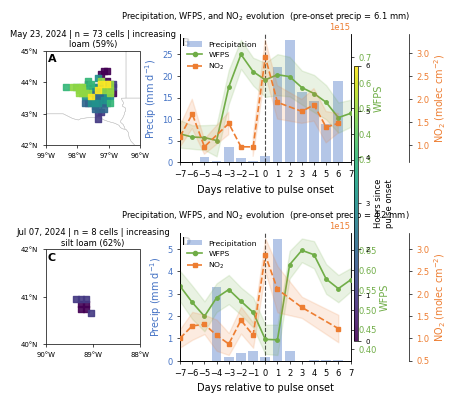

Saved.


In [11]:
#stuff
EXEMPLAR_EVENTS = [733, 1674]
WINDOW_DAYS = 7
pulse_df= groups_df.copy()

# ── Validate ──────────────────────────────────────────────────────────────────
EXEMPLAR_EVENTS = [e for e in EXEMPLAR_EVENTS if e in pulse_df["group_id"].unique()]
assert len(EXEMPLAR_EVENTS) > 0

n_events = len(EXEMPLAR_EVENTS)
panel_labels = list("ABCDEFGHIJKLMNOPQRSTUVWXYZ")

# ── Global colour range ───────────────────────────────────────────────────────
all_ep = pulse_df[pulse_df["group_id"].isin(EXEMPLAR_EVENTS)].copy()
all_ep["hours_since_start"] = (
    all_ep["datetime"]
    - all_ep.groupby("group_id")["datetime"].transform("min")
).dt.total_seconds() / 3600
vmin_time, vmax_time = 0, all_ep["hours_since_start"].max()

# ── Figure — PNAS full-width (17.8 cm) ───────────────────────────────────────
cm = 1 / 2.54
fig_w = 8.7 * cm
fig_h = 5 * cm * n_events
fig = plt.figure(figsize=(fig_w, fig_h))
outer = gridspec.GridSpec(n_events, 1, hspace=0.55,
                             top=0.93, bottom=0.10, left=0.07, right=0.96)
map_axes = []
last_sc  = None

for row, eid in enumerate(EXEMPLAR_EVENTS):
    inner = gridspec.GridSpecFromSubplotSpec(
        1, 2, subplot_spec=outer[row],
        width_ratios=[1.0, 1.8], wspace=0.30
    )

    event_pulses = pulse_df[pulse_df["group_id"] == eid].copy()
    event_cells  = event_pulses[["grid_lat", "grid_lon"]].drop_duplicates()
    if event_pulses.empty:
        continue

    t0 = event_pulses["datetime"].min()
    event_pulses["hours_since_start"] = (
        (event_pulses["datetime"] - t0).dt.total_seconds() / 3600
    )

    # Soil texture
    soil_str = ""
    if "dominant_texture" in event_pulses.columns:
        es = (event_pulses[["grid_lat","grid_lon","dominant_texture"]]
              .drop_duplicates(subset=["grid_lat","grid_lon"])
              .dropna(subset=["dominant_texture"]))
        if len(es) > 0:
            vc = es["dominant_texture"].value_counts()
            soil_str = f"{vc.index[0]} ({vc.iloc[0]/vc.sum():.0%})"

    sm_label = event_pulses["sm_class"].iloc[0] if "sm_class" in event_pulses.columns else ""

    # ±7-day daily window
    sub = df.merge(event_cells, on=["grid_lat","grid_lon"], how="inner").copy()
    sub = sub[
        (sub["datetime"] >= t0 - pd.Timedelta(days=WINDOW_DAYS)) &
        (sub["datetime"] <= t0 + pd.Timedelta(days=WINDOW_DAYS))
    ].copy()
    sub["lag_day"] = np.floor(
        (sub["datetime"] - t0).dt.total_seconds() / 86400.0
    ).astype(int)

    agg_cell = {"precip": ("h_precip_mm","sum"), "no2": ("no2_mean","mean")}
    if "WFPS_c" in sub.columns:
        agg_cell["wfps"] = ("WFPS_c","mean")
    cell_daily = sub.groupby(["grid_lat","grid_lon","lag_day"]).agg(**agg_cell).reset_index()

    agg_event = {
        "precip_mean": ("precip","mean"), "precip_std": ("precip","std"),
        "no2_mean":    ("no2","mean"),    "no2_std":    ("no2","std"),
    }
    if "wfps" in cell_daily.columns:
        agg_event["wfps_mean"] = ("wfps","mean")
        agg_event["wfps_std"]  = ("wfps","std")
    event_daily = cell_daily.groupby("lag_day").agg(**agg_event).reset_index()
    full_lags   = pd.DataFrame({"lag_day": np.arange(-WINDOW_DAYS, WINDOW_DAYS+1)})
    event_daily = full_lags.merge(event_daily, on="lag_day", how="left")
    event_daily[["precip_mean","precip_std"]] = (
        event_daily[["precip_mean","precip_std"]].fillna(0)
    )

    # ── MAP ───────────────────────────────────────────────────────────────────
    ax_map = fig.add_subplot(inner[0], projection=ccrs.PlateCarree())
    map_axes.append(ax_map)

    lon_min = event_cells["grid_lon"].min() - 0.5
    lon_max = event_cells["grid_lon"].max() + 0.5
    lat_min = event_cells["grid_lat"].min() - 0.5
    lat_max = event_cells["grid_lat"].max() + 0.5
    ax_map.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())
    ax_map.add_feature(cfeature.LAND.with_scale("50m"),   facecolor="white",  zorder=1)
    ax_map.add_feature(cfeature.STATES.with_scale("50m"), edgecolor="silver", linewidth=0.3, zorder=2)
    ax_map.add_feature(cfeature.BORDERS.with_scale("50m"),edgecolor="black",  linewidth=0.4, zorder=3)
    ax_map.coastlines(resolution="50m", linewidth=0.3, zorder=4)

    sc = ax_map.scatter(
        event_pulses["grid_lon"], event_pulses["grid_lat"],
        c=event_pulses["hours_since_start"], cmap="viridis",
        vmin=vmin_time, vmax=vmax_time,
        s=18, marker="s", alpha=0.9, transform=ccrs.PlateCarree(), zorder=5
    )
    last_sc = sc

    xticks = np.arange(np.floor(lon_min), np.ceil(lon_max) + 1, 1)
    yticks = np.arange(np.floor(lat_min), np.ceil(lat_max) + 1, 1)
    ax_map.set_xticks(xticks, crs=ccrs.PlateCarree())
    ax_map.set_yticks(yticks, crs=ccrs.PlateCarree())
    ax_map.xaxis.set_major_formatter(cticker.LongitudeFormatter())
    ax_map.yaxis.set_major_formatter(cticker.LatitudeFormatter())
    ax_map.tick_params(labelsize=5)

    # Panel label (A, B, C...)
    ax_map.text(0.02, 0.97, panel_labels[row*2],
                transform=ax_map.transAxes,
                fontsize=8, fontweight="bold", va="top", ha="left")

    # Clean title: date, size, sm class, soil
    sm_str = f" | {sm_label}" if sm_label else ""
    ax_map.set_title(
        f"{t0:%b %d, %Y} | n = {len(event_cells)} cells{sm_str}\n{soil_str}",
        fontsize=6, pad=3
    )

    # ── TIME SERIES ───────────────────────────────────────────────────────────
    ax_ts = fig.add_subplot(inner[1])

    # Precipitation bars
    ax_ts.bar(event_daily["lag_day"], event_daily["precip_mean"],
              color="#4472C4", alpha=0.4, width=0.8, zorder=2)
    ax_ts.set_ylabel("Precip (mm d$^{-1}$)", color="#4472C4", labelpad=2)
    ax_ts.tick_params(axis="y", labelcolor="#4472C4")
    ax_ts.axvline(0, color="black", linestyle="--", linewidth=0.8, alpha=0.7, zorder=3)
    ax_ts.spines[["top"]].set_visible(False)
    ax_ts.set_xlim(-WINDOW_DAYS, WINDOW_DAYS)
    ax_ts.set_xticks(np.arange(-WINDOW_DAYS, WINDOW_DAYS + 1, 1))
    ax_ts.set_xlabel("Days relative to pulse onset")

    # WFPS
    has_wfps = "wfps_mean" in event_daily.columns
    if has_wfps:
        ax_wfps = ax_ts.twinx()
        vm = event_daily["wfps_mean"].notna()
        ax_wfps.plot(event_daily.loc[vm, "lag_day"],
                     event_daily.loc[vm, "wfps_mean"],
                     color="#70AD47", linewidth=1.2, marker="o",
                     markersize=2.5, label="WFPS", zorder=4)
        ax_wfps.fill_between(
            event_daily.loc[vm, "lag_day"],
            (event_daily["wfps_mean"] - event_daily["wfps_std"]).loc[vm],
            (event_daily["wfps_mean"] + event_daily["wfps_std"]).loc[vm],
            color="#70AD47", alpha=0.15
        )
        ax_wfps.set_ylabel("WFPS", color="#70AD47", labelpad=2)
        ax_wfps.tick_params(axis="y", labelcolor="#70AD47")
        ax_wfps.spines[["top"]].set_visible(False)

    # NO₂
    ax_no2 = ax_ts.twinx()
    if has_wfps:
        ax_no2.spines["right"].set_position(("outward", 42))
    vn = event_daily["no2_mean"].notna()
    ax_no2.plot(event_daily.loc[vn, "lag_day"],
                event_daily.loc[vn, "no2_mean"],
                color="#ED7D31", linestyle="--", linewidth=1.2,
                marker="s", markersize=2.5, label="NO$_2$", zorder=5)
    ax_no2.fill_between(
        event_daily.loc[vn, "lag_day"],
        (event_daily["no2_mean"] - event_daily["no2_std"]).loc[vn],
        (event_daily["no2_mean"] + event_daily["no2_std"]).loc[vn],
        color="#ED7D31", alpha=0.15
    )
    ax_no2.set_ylabel("NO$_2$ (molec cm$^{-2}$)", color="#ED7D31", labelpad=2)
    ax_no2.tick_params(axis="y", labelcolor="#ED7D31")
    ax_no2.spines[["top"]].set_visible(False)

    # Panel label for time series panel
    ax_ts.text(0.01, 0.97, panel_labels[row*2 + 1],
               transform=ax_ts.transAxes,
               fontsize=8, fontweight="bold", va="top", ha="left")

    # Clean title
    pre_precip = event_daily.loc[event_daily["lag_day"] < 0, "precip_mean"].sum()
    ax_ts.set_title(
        f"Precipitation, WFPS, and NO$_2$ evolution  "
        f"(pre-onset precip = {pre_precip:.1f} mm)",
        fontsize=6, pad=3
    )

    # Legend
    handles = [
        Patch(facecolor="#4472C4", alpha=0.4, label="Precipitation"),
    ]
    if has_wfps:
        handles.append(Line2D([0],[0], color="#70AD47", linewidth=1.2,
                               marker="o", markersize=3, label="WFPS"))
    handles.append(Line2D([0],[0], color="#ED7D31", linestyle="--",
                           linewidth=1.2, marker="s", markersize=3,
                           label="NO$_2$"))
    ax_ts.legend(handles=handles, fontsize=5.5, loc="upper left",
                 frameon=True, framealpha=0.85, edgecolor="none")

# ── Colorbar — vertical, right side ──────────────────────────────────────────
if last_sc is not None:
    cbar_ax = fig.add_axes([0.97, 0.15, 0.012, 0.70])  # [left, bottom, w, h]
    cbar = fig.colorbar(last_sc, cax=cbar_ax)
    cbar.set_label("Hours since\npulse onset", fontsize=6, labelpad=3)
    cbar.ax.tick_params(labelsize=5)

# ── Save ──────────────────────────────────────────────────────────────────────
fig.savefig("/global/home/users/toireasamarie/FINAL Paper Workflow/Paper Figures/exemplar_events_PNAS.pdf",
            dpi=600, bbox_inches="tight")
fig.savefig("/global/home/users/toireasamarie/FINAL Paper Workflow/Paper Figures/exemplar_events_PNAS.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved.")

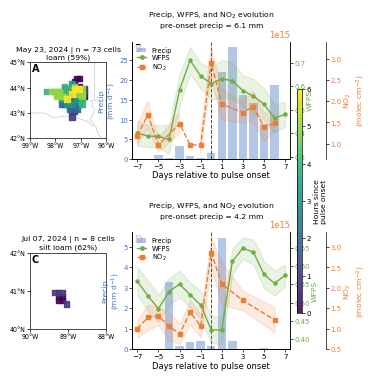

Saved.


In [13]:
#stuff
EXEMPLAR_EVENTS = [733, 1674]
WINDOW_DAYS = 7
pulse_df = groups_df.copy()

# ── Validate ──────────────────────────────────────────────────────────────────
EXEMPLAR_EVENTS = [e for e in EXEMPLAR_EVENTS if e in pulse_df["group_id"].unique()]
assert len(EXEMPLAR_EVENTS) > 0

n_events = len(EXEMPLAR_EVENTS)
panel_labels = list("ABCDEFGHIJKLMNOPQRSTUVWXYZ")

# ── Global colour range ───────────────────────────────────────────────────────
all_ep = pulse_df[pulse_df["group_id"].isin(EXEMPLAR_EVENTS)].copy()
all_ep["hours_since_start"] = (all_ep["datetime"] - all_ep.groupby("group_id")["datetime"].transform("min")).dt.total_seconds() / 3600
vmin_time, vmax_time = 0, all_ep["hours_since_start"].max()

# ── Figure — PNAS one-column width ────────────────────────────────────────────
cm = 1 / 2.54
fig_w = 8.7 * cm
fig_h = 4.6 * cm * n_events

fig = plt.figure(figsize=(fig_w, fig_h))
outer = gridspec.GridSpec(n_events, 1, hspace=0.62, top=0.95, bottom=0.10, left=0.12, right=0.88)

map_axes = []
last_sc = None

for row, eid in enumerate(EXEMPLAR_EVENTS):

    inner = gridspec.GridSpecFromSubplotSpec(1, 2, subplot_spec=outer[row], width_ratios=[0.78, 1.62], wspace=0.22)

    event_pulses = pulse_df[pulse_df["group_id"] == eid].copy()
    event_cells = event_pulses[["grid_lat", "grid_lon"]].drop_duplicates()

    if event_pulses.empty:
        continue

    t0 = event_pulses["datetime"].min()
    event_pulses["hours_since_start"] = (event_pulses["datetime"] - t0).dt.total_seconds() / 3600

    # Soil texture
    soil_str = ""

    if "dominant_texture" in event_pulses.columns:
        es = event_pulses[["grid_lat", "grid_lon", "dominant_texture"]].drop_duplicates(subset=["grid_lat", "grid_lon"]).dropna(subset=["dominant_texture"])

        if len(es) > 0:
            vc = es["dominant_texture"].value_counts()
            soil_str = f"{vc.index[0]} ({vc.iloc[0] / vc.sum():.0%})"

    sm_label = event_pulses["sm_class"].iloc[0] if "sm_class" in event_pulses.columns else ""

    # ±7-day daily window
    sub = df.merge(event_cells, on=["grid_lat", "grid_lon"], how="inner").copy()
    sub = sub[(sub["datetime"] >= t0 - pd.Timedelta(days=WINDOW_DAYS)) & (sub["datetime"] <= t0 + pd.Timedelta(days=WINDOW_DAYS))].copy()
    sub["lag_day"] = np.floor((sub["datetime"] - t0).dt.total_seconds() / 86400.0).astype(int)

    agg_cell = {"precip": ("h_precip_mm", "sum"), "no2": ("no2_mean", "mean")}

    if "WFPS_c" in sub.columns:
        agg_cell["wfps"] = ("WFPS_c", "mean")

    cell_daily = sub.groupby(["grid_lat", "grid_lon", "lag_day"]).agg(**agg_cell).reset_index()

    agg_event = {"precip_mean": ("precip", "mean"), "precip_std": ("precip", "std"), "no2_mean": ("no2", "mean"), "no2_std": ("no2", "std")}

    if "wfps" in cell_daily.columns:
        agg_event["wfps_mean"] = ("wfps", "mean")
        agg_event["wfps_std"] = ("wfps", "std")

    event_daily = cell_daily.groupby("lag_day").agg(**agg_event).reset_index()
    full_lags = pd.DataFrame({"lag_day": np.arange(-WINDOW_DAYS, WINDOW_DAYS + 1)})
    event_daily = full_lags.merge(event_daily, on="lag_day", how="left")
    event_daily[["precip_mean", "precip_std"]] = event_daily[["precip_mean", "precip_std"]].fillna(0)

    # ── MAP ───────────────────────────────────────────────────────────────────
    ax_map = fig.add_subplot(inner[0], projection=ccrs.PlateCarree())
    map_axes.append(ax_map)

    lon_min = event_cells["grid_lon"].min() - 0.45
    lon_max = event_cells["grid_lon"].max() + 0.45
    lat_min = event_cells["grid_lat"].min() - 0.45
    lat_max = event_cells["grid_lat"].max() + 0.45

    ax_map.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())
    ax_map.add_feature(cfeature.LAND.with_scale("50m"), facecolor="white", zorder=1)
    ax_map.add_feature(cfeature.STATES.with_scale("50m"), edgecolor="silver", linewidth=0.25, zorder=2)
    ax_map.add_feature(cfeature.BORDERS.with_scale("50m"), edgecolor="black", linewidth=0.3, zorder=3)
    ax_map.coastlines(resolution="50m", linewidth=0.25, zorder=4)

    sc = ax_map.scatter(event_pulses["grid_lon"], event_pulses["grid_lat"], c=event_pulses["hours_since_start"], cmap="viridis", vmin=vmin_time, vmax=vmax_time, s=15, marker="s", alpha=0.9, transform=ccrs.PlateCarree(), zorder=5)
    last_sc = sc

    xticks = np.arange(np.floor(lon_min), np.ceil(lon_max) + 1, 1)
    yticks = np.arange(np.floor(lat_min), np.ceil(lat_max) + 1, 1)

    ax_map.set_xticks(xticks, crs=ccrs.PlateCarree())
    ax_map.set_yticks(yticks, crs=ccrs.PlateCarree())
    ax_map.xaxis.set_major_formatter(cticker.LongitudeFormatter())
    ax_map.yaxis.set_major_formatter(cticker.LatitudeFormatter())
    ax_map.tick_params(labelsize=4.5, pad=1, length=2)

    sm_str = f" | {sm_label}" if sm_label else ""
    ax_map.set_title(f"{t0:%b %d, %Y} | n = {len(event_cells)} cells\n{soil_str}", fontsize=5.5, pad=2)

    ax_map.text(0.02, 0.98, panel_labels[row * 2], transform=ax_map.transAxes, fontsize=7, fontweight="bold", va="top", ha="left")

    # ── TIME SERIES ───────────────────────────────────────────────────────────
    ax_ts = fig.add_subplot(inner[1])

    ax_ts.bar(event_daily["lag_day"], event_daily["precip_mean"], color="#4472C4", alpha=0.4, width=0.8, zorder=2)
    ax_ts.set_ylabel("Precip\n(mm d$^{-1}$)", color="#4472C4", labelpad=1, fontsize=5.5)
    ax_ts.tick_params(axis="y", labelcolor="#4472C4", labelsize=5, pad=1, length=2)
    ax_ts.tick_params(axis="x", labelsize=5, pad=1, length=2)
    ax_ts.axvline(0, color="black", linestyle="--", linewidth=0.7, alpha=0.7, zorder=3)
    ax_ts.spines[["top"]].set_visible(False)
    ax_ts.set_xlim(-WINDOW_DAYS - 0.5, WINDOW_DAYS + 0.5)
    ax_ts.set_xticks(np.arange(-WINDOW_DAYS, WINDOW_DAYS + 1, 2))
    ax_ts.set_xlabel("Days relative to pulse onset", fontsize=6, labelpad=1)

    has_wfps = "wfps_mean" in event_daily.columns

    if has_wfps:
        ax_wfps = ax_ts.twinx()
        vm = event_daily["wfps_mean"].notna()

        ax_wfps.plot(event_daily.loc[vm, "lag_day"], event_daily.loc[vm, "wfps_mean"], color="#70AD47", linewidth=1.0, marker="o", markersize=2.2, label="WFPS", zorder=4)
        ax_wfps.fill_between(event_daily.loc[vm, "lag_day"], (event_daily["wfps_mean"] - event_daily["wfps_std"]).loc[vm], (event_daily["wfps_mean"] + event_daily["wfps_std"]).loc[vm], color="#70AD47", alpha=0.15)

        ax_wfps.set_ylabel("WFPS", color="#70AD47", labelpad=1, fontsize=5.5)
        ax_wfps.tick_params(axis="y", labelcolor="#70AD47", labelsize=5, pad=1, length=2)
        ax_wfps.spines[["top"]].set_visible(False)

    ax_no2 = ax_ts.twinx()

    if has_wfps:
        ax_no2.spines["right"].set_position(("outward", 26))

    vn = event_daily["no2_mean"].notna()

    ax_no2.plot(event_daily.loc[vn, "lag_day"], event_daily.loc[vn, "no2_mean"], color="#ED7D31", linestyle="--", linewidth=1.0, marker="s", markersize=2.2, label="NO$_2$", zorder=5)
    ax_no2.fill_between(event_daily.loc[vn, "lag_day"], (event_daily["no2_mean"] - event_daily["no2_std"]).loc[vn], (event_daily["no2_mean"] + event_daily["no2_std"]).loc[vn], color="#ED7D31", alpha=0.15)

    ax_no2.set_ylabel("NO$_2$\n(molec cm$^{-2}$)", color="#ED7D31", labelpad=1, fontsize=5.5)
    ax_no2.tick_params(axis="y", labelcolor="#ED7D31", labelsize=5, pad=1, length=2)
    ax_no2.spines[["top"]].set_visible(False)

    ax_ts.text(0.01, 0.98, panel_labels[row * 2 + 1], transform=ax_ts.transAxes, fontsize=7, fontweight="bold", va="top", ha="left")

    pre_precip = event_daily.loc[event_daily["lag_day"] < 0, "precip_mean"].sum()
    ax_ts.set_title(f"Precip, WFPS, and NO$_2$ evolution\npre-onset precip = {pre_precip:.1f} mm", fontsize=5.5, pad=2)

    handles = [Patch(facecolor="#4472C4", alpha=0.4, label="Precip")]

    if has_wfps:
        handles.append(Line2D([0], [0], color="#70AD47", linewidth=1.0, marker="o", markersize=2.5, label="WFPS"))

    handles.append(Line2D([0], [0], color="#ED7D31", linestyle="--", linewidth=1.0, marker="s", markersize=2.5, label="NO$_2$"))

    ax_ts.legend(handles=handles, fontsize=4.8, loc="upper left", frameon=True, framealpha=0.85, edgecolor="none", handlelength=1.4, borderpad=0.25, labelspacing=0.2)


# ── Colorbar — inside figure, not outside clipped area ────────────────────────
if last_sc is not None:
    cbar_ax = fig.add_axes([0.90, 0.20, 0.015, 0.62])
    cbar = fig.colorbar(last_sc, cax=cbar_ax)
    cbar.set_label("Hours since\npulse onset", fontsize=5.5, labelpad=2)
    cbar.ax.tick_params(labelsize=5, pad=1, length=2)


# ── Save ──────────────────────────────────────────────────────────────────────
fig.savefig("/global/home/users/toireasamarie/FINAL Paper Workflow/Paper Figures/exemplar_events_PNAS.pdf", dpi=600)
fig.savefig("/global/home/users/toireasamarie/FINAL Paper Workflow/Paper Figures/exemplar_events_PNAS.png", dpi=300)
plt.show()

print("Saved.")

In [15]:
from matplotlib.patches import Rectangle
from matplotlib.collections import PatchCollection

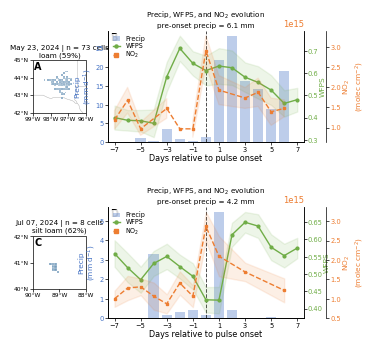

Saved.


In [17]:
#stuff
EXEMPLAR_EVENTS = [733, 1674]
WINDOW_DAYS = 7
pulse_df = groups_df.copy()

# ── Validate ──────────────────────────────────────────────────────────────────
EXEMPLAR_EVENTS = [e for e in EXEMPLAR_EVENTS if e in pulse_df["group_id"].unique()]
assert len(EXEMPLAR_EVENTS) > 0

n_events = len(EXEMPLAR_EVENTS)
panel_labels = list("ABCDEFGHIJKLMNOPQRSTUVWXYZ")

# ── Figure — PNAS one-column width ────────────────────────────────────────────
cm = 1 / 2.54
fig_w = 8.7 * cm
fig_h = 4.3 * cm * n_events

fig = plt.figure(figsize=(fig_w, fig_h))
outer = gridspec.GridSpec(n_events, 1, hspace=0.58, top=0.95, bottom=0.10, left=0.11, right=0.90)

map_axes = []

for row, eid in enumerate(EXEMPLAR_EVENTS):

    inner = gridspec.GridSpecFromSubplotSpec(1, 2, subplot_spec=outer[row], width_ratios=[0.55, 2.05], wspace=0.18)

    event_pulses = pulse_df[pulse_df["group_id"] == eid].copy()
    event_cells = event_pulses[["grid_lat", "grid_lon"]].drop_duplicates()

    if event_pulses.empty:
        continue

    t0 = event_pulses["datetime"].min()

    # Soil texture
    soil_str = ""

    if "dominant_texture" in event_pulses.columns:
        es = event_pulses[["grid_lat", "grid_lon", "dominant_texture"]].drop_duplicates(subset=["grid_lat", "grid_lon"]).dropna(subset=["dominant_texture"])

        if len(es) > 0:
            vc = es["dominant_texture"].value_counts()
            soil_str = f"{vc.index[0]} ({vc.iloc[0] / vc.sum():.0%})"

    sm_label = event_pulses["sm_class"].iloc[0] if "sm_class" in event_pulses.columns else ""

    # ±7-day daily window
    sub = df.merge(event_cells, on=["grid_lat", "grid_lon"], how="inner").copy()
    sub = sub[(sub["datetime"] >= t0 - pd.Timedelta(days=WINDOW_DAYS)) & (sub["datetime"] <= t0 + pd.Timedelta(days=WINDOW_DAYS))].copy()
    sub["lag_day"] = np.floor((sub["datetime"] - t0).dt.total_seconds() / 86400.0).astype(int)

    agg_cell = {"precip": ("h_precip_mm", "sum"), "no2": ("no2_mean", "mean")}

    if "WFPS_c" in sub.columns:
        agg_cell["wfps"] = ("WFPS_c", "mean")

    cell_daily = sub.groupby(["grid_lat", "grid_lon", "lag_day"]).agg(**agg_cell).reset_index()

    agg_event = {"precip_mean": ("precip", "mean"), "precip_std": ("precip", "std"), "no2_mean": ("no2", "mean"), "no2_std": ("no2", "std")}

    if "wfps" in cell_daily.columns:
        agg_event["wfps_mean"] = ("wfps", "mean")
        agg_event["wfps_std"] = ("wfps", "std")

    event_daily = cell_daily.groupby("lag_day").agg(**agg_event).reset_index()
    full_lags = pd.DataFrame({"lag_day": np.arange(-WINDOW_DAYS, WINDOW_DAYS + 1)})
    event_daily = full_lags.merge(event_daily, on="lag_day", how="left")
    event_daily[["precip_mean", "precip_std"]] = event_daily[["precip_mean", "precip_std"]].fillna(0)

    # ── MAP ───────────────────────────────────────────────────────────────────
    ax_map = fig.add_subplot(inner[0], projection=ccrs.PlateCarree())
    map_axes.append(ax_map)

    lon_min = event_cells["grid_lon"].min() - 0.45
    lon_max = event_cells["grid_lon"].max() + 0.45
    lat_min = event_cells["grid_lat"].min() - 0.45
    lat_max = event_cells["grid_lat"].max() + 0.45

    ax_map.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())
    ax_map.add_feature(cfeature.LAND.with_scale("50m"), facecolor="white", zorder=1)
    ax_map.add_feature(cfeature.STATES.with_scale("50m"), edgecolor="silver", linewidth=0.25, zorder=2)
    ax_map.add_feature(cfeature.BORDERS.with_scale("50m"), edgecolor="black", linewidth=0.3, zorder=3)
    ax_map.coastlines(resolution="50m", linewidth=0.25, zorder=4)

    footprint_cell_w = 0.1
    footprint_cell_h = 0.1
    rects = []

    for lon, lat in zip(event_cells["grid_lon"], event_cells["grid_lat"]):
        rects.append(Rectangle((lon - footprint_cell_w / 2, lat - footprint_cell_h / 2), footprint_cell_w, footprint_cell_h))

    pc = PatchCollection(rects, facecolor="#6E97B8", edgecolor="white", alpha=0.95, linewidth=0.2, zorder=5)
    pc.set_transform(ccrs.PlateCarree())
    ax_map.add_collection(pc)

    xticks = np.arange(np.floor(lon_min), np.ceil(lon_max) + 1, 1)
    yticks = np.arange(np.floor(lat_min), np.ceil(lat_max) + 1, 1)

    ax_map.set_xticks(xticks, crs=ccrs.PlateCarree())
    ax_map.set_yticks(yticks, crs=ccrs.PlateCarree())
    ax_map.xaxis.set_major_formatter(cticker.LongitudeFormatter())
    ax_map.yaxis.set_major_formatter(cticker.LatitudeFormatter())
    ax_map.tick_params(labelsize=4.3, pad=1, length=2)

    ax_map.set_title(f"{t0:%b %d, %Y} | n = {len(event_cells)} cells\n{soil_str}", fontsize=5.2, pad=2)
    ax_map.text(0.02, 0.98, panel_labels[row * 2], transform=ax_map.transAxes, fontsize=7, fontweight="bold", va="top", ha="left")

    # ── TIME SERIES ───────────────────────────────────────────────────────────
    ax_ts = fig.add_subplot(inner[1])

    ax_ts.bar(event_daily["lag_day"], event_daily["precip_mean"], color="#4472C4", alpha=0.35, width=0.8, zorder=2)
    ax_ts.set_ylabel("Precip\n(mm d$^{-1}$)", color="#4472C4", labelpad=1, fontsize=5.3)
    ax_ts.tick_params(axis="y", labelcolor="#4472C4", labelsize=4.8, pad=1, length=2)
    ax_ts.tick_params(axis="x", labelsize=4.8, pad=1, length=2)
    ax_ts.axvline(0, color="black", linestyle="--", linewidth=0.7, alpha=0.7, zorder=3)
    ax_ts.spines[["top"]].set_visible(False)
    ax_ts.set_xlim(-WINDOW_DAYS - 0.5, WINDOW_DAYS + 0.5)
    ax_ts.set_xticks(np.arange(-WINDOW_DAYS, WINDOW_DAYS + 1, 2))
    ax_ts.set_xlabel("Days relative to pulse onset", fontsize=5.8, labelpad=1)

    has_wfps = "wfps_mean" in event_daily.columns

    if has_wfps:
        ax_wfps = ax_ts.twinx()
        vm = event_daily["wfps_mean"].notna()

        ax_wfps.plot(event_daily.loc[vm, "lag_day"], event_daily.loc[vm, "wfps_mean"], color="#70AD47", linewidth=1.0, marker="o", markersize=2.0, label="WFPS", zorder=4)
        ax_wfps.fill_between(event_daily.loc[vm, "lag_day"], (event_daily["wfps_mean"] - event_daily["wfps_std"]).loc[vm], (event_daily["wfps_mean"] + event_daily["wfps_std"]).loc[vm], color="#70AD47", alpha=0.12)

        ax_wfps.set_ylabel("WFPS", color="#70AD47", labelpad=1, fontsize=5.3)
        ax_wfps.tick_params(axis="y", labelcolor="#70AD47", labelsize=4.8, pad=1, length=2)
        ax_wfps.spines[["top"]].set_visible(False)

    ax_no2 = ax_ts.twinx()

    if has_wfps:
        ax_no2.spines["right"].set_position(("outward", 16))

    vn = event_daily["no2_mean"].notna()

    ax_no2.plot(event_daily.loc[vn, "lag_day"], event_daily.loc[vn, "no2_mean"], color="#ED7D31", linestyle="--", linewidth=1.0, marker="s", markersize=2.0, label="NO$_2$", zorder=5)
    ax_no2.fill_between(event_daily.loc[vn, "lag_day"], (event_daily["no2_mean"] - event_daily["no2_std"]).loc[vn], (event_daily["no2_mean"] + event_daily["no2_std"]).loc[vn], color="#ED7D31", alpha=0.12)

    ax_no2.set_ylabel("NO$_2$\n(molec cm$^{-2}$)", color="#ED7D31", labelpad=1, fontsize=5.3)
    ax_no2.tick_params(axis="y", labelcolor="#ED7D31", labelsize=4.8, pad=1, length=2)
    ax_no2.spines[["top"]].set_visible(False)

    ax_ts.text(0.01, 0.98, panel_labels[row * 2 + 1], transform=ax_ts.transAxes, fontsize=7, fontweight="bold", va="top", ha="left")

    pre_precip = event_daily.loc[event_daily["lag_day"] < 0, "precip_mean"].sum()
    ax_ts.set_title(f"Precip, WFPS, and NO$_2$ evolution\npre-onset precip = {pre_precip:.1f} mm", fontsize=5.2, pad=2)

    handles = [Patch(facecolor="#4472C4", alpha=0.35, label="Precip")]

    if has_wfps:
        handles.append(Line2D([0], [0], color="#70AD47", linewidth=1.0, marker="o", markersize=2.2, label="WFPS"))

    handles.append(Line2D([0], [0], color="#ED7D31", linestyle="--", linewidth=1.0, marker="s", markersize=2.2, label="NO$_2$"))

    ax_ts.legend(handles=handles, fontsize=4.6, loc="upper left", frameon=True, framealpha=0.85, edgecolor="none", handlelength=1.2, borderpad=0.2, labelspacing=0.15)

# ── Save ──────────────────────────────────────────────────────────────────────
fig.savefig("/global/home/users/toireasamarie/FINAL Paper Workflow/Paper Figures/exemplar_events_PNAS.pdf", dpi=600)
fig.savefig("/global/home/users/toireasamarie/FINAL Paper Workflow/Paper Figures/exemplar_events_PNAS.png", dpi=300)
plt.show()

print("Saved.")

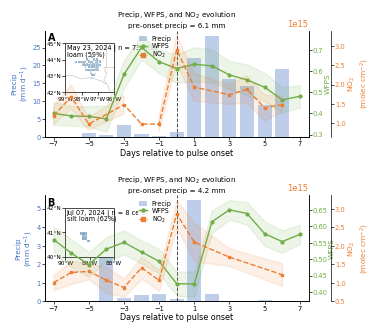

Saved.


In [18]:
#stuff
from matplotlib.patches import Rectangle, Patch
from matplotlib.collections import PatchCollection
from matplotlib.lines import Line2D

EXEMPLAR_EVENTS = [733, 1674]
WINDOW_DAYS = 7
pulse_df = groups_df.copy()

# ── Validate ──────────────────────────────────────────────────────────────────
EXEMPLAR_EVENTS = [e for e in EXEMPLAR_EVENTS if e in pulse_df["group_id"].unique()]
assert len(EXEMPLAR_EVENTS) > 0

n_events = len(EXEMPLAR_EVENTS)
panel_labels = list("ABCDEFGHIJKLMNOPQRSTUVWXYZ")

# ── Figure — PNAS one-column width ────────────────────────────────────────────
cm = 1 / 2.54
fig_w = 8.7 * cm
fig_h = 4.0 * cm * n_events

fig = plt.figure(figsize=(fig_w, fig_h))
outer = gridspec.GridSpec(n_events, 1, hspace=0.55, top=0.96, bottom=0.10, left=0.13, right=0.90)

for row, eid in enumerate(EXEMPLAR_EVENTS):

    event_pulses = pulse_df[pulse_df["group_id"] == eid].copy()
    event_cells = event_pulses[["grid_lat", "grid_lon"]].drop_duplicates()

    if event_pulses.empty:
        continue

    t0 = event_pulses["datetime"].min()

    # Soil texture
    soil_str = ""

    if "dominant_texture" in event_pulses.columns:
        es = event_pulses[["grid_lat", "grid_lon", "dominant_texture"]].drop_duplicates(subset=["grid_lat", "grid_lon"]).dropna(subset=["dominant_texture"])

        if len(es) > 0:
            vc = es["dominant_texture"].value_counts()
            soil_str = f"{vc.index[0]} ({vc.iloc[0] / vc.sum():.0%})"

    sm_label = event_pulses["sm_class"].iloc[0] if "sm_class" in event_pulses.columns else ""

    # ±7-day daily window
    sub = df.merge(event_cells, on=["grid_lat", "grid_lon"], how="inner").copy()
    sub = sub[(sub["datetime"] >= t0 - pd.Timedelta(days=WINDOW_DAYS)) & (sub["datetime"] <= t0 + pd.Timedelta(days=WINDOW_DAYS))].copy()
    sub["lag_day"] = np.floor((sub["datetime"] - t0).dt.total_seconds() / 86400.0).astype(int)

    agg_cell = {"precip": ("h_precip_mm", "sum"), "no2": ("no2_mean", "mean")}

    if "WFPS_c" in sub.columns:
        agg_cell["wfps"] = ("WFPS_c", "mean")

    cell_daily = sub.groupby(["grid_lat", "grid_lon", "lag_day"]).agg(**agg_cell).reset_index()

    agg_event = {"precip_mean": ("precip", "mean"), "precip_std": ("precip", "std"), "no2_mean": ("no2", "mean"), "no2_std": ("no2", "std")}

    if "wfps" in cell_daily.columns:
        agg_event["wfps_mean"] = ("wfps", "mean")
        agg_event["wfps_std"] = ("wfps", "std")

    event_daily = cell_daily.groupby("lag_day").agg(**agg_event).reset_index()
    full_lags = pd.DataFrame({"lag_day": np.arange(-WINDOW_DAYS, WINDOW_DAYS + 1)})
    event_daily = full_lags.merge(event_daily, on="lag_day", how="left")
    event_daily[["precip_mean", "precip_std"]] = event_daily[["precip_mean", "precip_std"]].fillna(0)

    # ── TIME SERIES MAIN PANEL ────────────────────────────────────────────────
    ax_ts = fig.add_subplot(outer[row])

    ax_ts.bar(event_daily["lag_day"], event_daily["precip_mean"], color="#4472C4", alpha=0.35, width=0.8, zorder=2)
    ax_ts.set_ylabel("Precip\n(mm d$^{-1}$)", color="#4472C4", labelpad=1, fontsize=5.3)
    ax_ts.tick_params(axis="y", labelcolor="#4472C4", labelsize=4.8, pad=1, length=2)
    ax_ts.tick_params(axis="x", labelsize=4.8, pad=1, length=2)
    ax_ts.axvline(0, color="black", linestyle="--", linewidth=0.7, alpha=0.7, zorder=3)
    ax_ts.spines[["top"]].set_visible(False)
    ax_ts.set_xlim(-WINDOW_DAYS - 0.5, WINDOW_DAYS + 0.5)
    ax_ts.set_xticks(np.arange(-WINDOW_DAYS, WINDOW_DAYS + 1, 2))
    ax_ts.set_xlabel("Days relative to pulse onset", fontsize=5.8, labelpad=1)

    has_wfps = "wfps_mean" in event_daily.columns

    if has_wfps:
        ax_wfps = ax_ts.twinx()
        vm = event_daily["wfps_mean"].notna()
        ax_wfps.plot(event_daily.loc[vm, "lag_day"], event_daily.loc[vm, "wfps_mean"], color="#70AD47", linewidth=1.0, marker="o", markersize=2.0, label="WFPS", zorder=4)
        ax_wfps.fill_between(event_daily.loc[vm, "lag_day"], (event_daily["wfps_mean"] - event_daily["wfps_std"]).loc[vm], (event_daily["wfps_mean"] + event_daily["wfps_std"]).loc[vm], color="#70AD47", alpha=0.12)
        ax_wfps.set_ylabel("WFPS", color="#70AD47", labelpad=1, fontsize=5.3)
        ax_wfps.tick_params(axis="y", labelcolor="#70AD47", labelsize=4.8, pad=1, length=2)
        ax_wfps.spines[["top"]].set_visible(False)

    ax_no2 = ax_ts.twinx()

    if has_wfps:
        ax_no2.spines["right"].set_position(("outward", 16))

    vn = event_daily["no2_mean"].notna()
    ax_no2.plot(event_daily.loc[vn, "lag_day"], event_daily.loc[vn, "no2_mean"], color="#ED7D31", linestyle="--", linewidth=1.0, marker="s", markersize=2.0, label="NO$_2$", zorder=5)
    ax_no2.fill_between(event_daily.loc[vn, "lag_day"], (event_daily["no2_mean"] - event_daily["no2_std"]).loc[vn], (event_daily["no2_mean"] + event_daily["no2_std"]).loc[vn], color="#ED7D31", alpha=0.12)
    ax_no2.set_ylabel("NO$_2$\n(molec cm$^{-2}$)", color="#ED7D31", labelpad=1, fontsize=5.3)
    ax_no2.tick_params(axis="y", labelcolor="#ED7D31", labelsize=4.8, pad=1, length=2)
    ax_no2.spines[["top"]].set_visible(False)

    pre_precip = event_daily.loc[event_daily["lag_day"] < 0, "precip_mean"].sum()
    ax_ts.set_title(f"Precip, WFPS, and NO$_2$ evolution\npre-onset precip = {pre_precip:.1f} mm", fontsize=5.2, pad=2)

    ax_ts.text(0.01, 0.98, panel_labels[row], transform=ax_ts.transAxes, fontsize=7, fontweight="bold", va="top", ha="left")

    handles = [Patch(facecolor="#4472C4", alpha=0.35, label="Precip")]

    if has_wfps:
        handles.append(Line2D([0], [0], color="#70AD47", linewidth=1.0, marker="o", markersize=2.2, label="WFPS"))

    handles.append(Line2D([0], [0], color="#ED7D31", linestyle="--", linewidth=1.0, marker="s", markersize=2.2, label="NO$_2$"))

    ax_ts.legend(handles=handles, fontsize=4.6, loc="upper left", bbox_to_anchor=(0.34, 1.00), frameon=True, framealpha=0.85, edgecolor="none", handlelength=1.2, borderpad=0.2, labelspacing=0.15)

    # ── MAP INSET ─────────────────────────────────────────────────────────────
    ax_map = ax_ts.inset_axes([0.03, 0.42, 0.28, 0.46], projection=ccrs.PlateCarree())

    lon_min = event_cells["grid_lon"].min() - 0.45
    lon_max = event_cells["grid_lon"].max() + 0.45
    lat_min = event_cells["grid_lat"].min() - 0.45
    lat_max = event_cells["grid_lat"].max() + 0.45

    ax_map.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())
    ax_map.add_feature(cfeature.LAND.with_scale("50m"), facecolor="white", zorder=1)
    ax_map.add_feature(cfeature.STATES.with_scale("50m"), edgecolor="silver", linewidth=0.25, zorder=2)
    ax_map.add_feature(cfeature.BORDERS.with_scale("50m"), edgecolor="black", linewidth=0.3, zorder=3)
    ax_map.coastlines(resolution="50m", linewidth=0.25, zorder=4)

    footprint_cell_w = 0.1
    footprint_cell_h = 0.1
    rects = []

    for lon, lat in zip(event_cells["grid_lon"], event_cells["grid_lat"]):
        rects.append(Rectangle((lon - footprint_cell_w / 2, lat - footprint_cell_h / 2), footprint_cell_w, footprint_cell_h))

    pc = PatchCollection(rects, facecolor="#6E97B8", edgecolor="white", alpha=0.95, linewidth=0.2, zorder=5)
    pc.set_transform(ccrs.PlateCarree())
    ax_map.add_collection(pc)

    xticks = np.arange(np.floor(lon_min), np.ceil(lon_max) + 1, 1)
    yticks = np.arange(np.floor(lat_min), np.ceil(lat_max) + 1, 1)

    ax_map.set_xticks(xticks, crs=ccrs.PlateCarree())
    ax_map.set_yticks(yticks, crs=ccrs.PlateCarree())
    ax_map.xaxis.set_major_formatter(cticker.LongitudeFormatter())
    ax_map.yaxis.set_major_formatter(cticker.LatitudeFormatter())
    ax_map.tick_params(labelsize=4.2, pad=1, length=2)

    ax_map.text(0.03, 0.97, f"{t0:%b %d, %Y} | n = {len(event_cells)} cells", transform=ax_map.transAxes, fontsize=4.7, va="top", ha="left")
    ax_map.text(0.03, 0.84, soil_str, transform=ax_map.transAxes, fontsize=4.7, va="top", ha="left")

# ── Save ──────────────────────────────────────────────────────────────────────
fig.savefig("/global/home/users/toireasamarie/FINAL Paper Workflow/Paper Figures/exemplar_events_PNAS.pdf", dpi=600)
fig.savefig("/global/home/users/toireasamarie/FINAL Paper Workflow/Paper Figures/exemplar_events_PNAS.png", dpi=300)
plt.show()

print("Saved.")

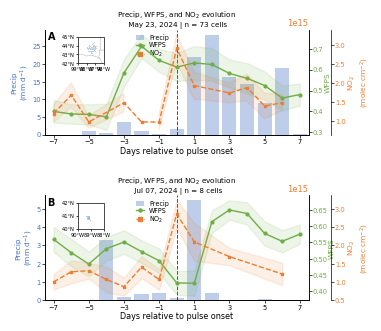

Saved.


In [22]:
# imports needed for footprint inset
from matplotlib.patches import Rectangle, Patch
from matplotlib.collections import PatchCollection
from matplotlib.lines import Line2D

#stuff
EXEMPLAR_EVENTS = [733, 1674]
WINDOW_DAYS = 7
pulse_df = groups_df.copy()

# ── Validate ──────────────────────────────────────────────────────────────────
EXEMPLAR_EVENTS = [e for e in EXEMPLAR_EVENTS if e in pulse_df["group_id"].unique()]
assert len(EXEMPLAR_EVENTS) > 0

n_events = len(EXEMPLAR_EVENTS)
panel_labels = list("ABCDEFGHIJKLMNOPQRSTUVWXYZ")

# ── Figure — PNAS one-column width ────────────────────────────────────────────
cm = 1 / 2.54
fig_w = 8.7 * cm
fig_h = 4.0 * cm * n_events

fig = plt.figure(figsize=(fig_w, fig_h))
outer = gridspec.GridSpec(n_events, 1, hspace=0.58, top=0.96, bottom=0.10, left=0.13, right=0.90)

for row, eid in enumerate(EXEMPLAR_EVENTS):

    event_pulses = pulse_df[pulse_df["group_id"] == eid].copy()
    event_cells = event_pulses[["grid_lat", "grid_lon"]].drop_duplicates()

    if event_pulses.empty:
        continue

    t0 = event_pulses["datetime"].min()

    # Soil texture
    soil_str = ""

    if "dominant_texture" in event_pulses.columns:
        es = event_pulses[["grid_lat", "grid_lon", "dominant_texture"]].drop_duplicates(subset=["grid_lat", "grid_lon"]).dropna(subset=["dominant_texture"])

        if len(es) > 0:
            vc = es["dominant_texture"].value_counts()
            soil_str = f"{vc.index[0]} ({vc.iloc[0] / vc.sum():.0%})"

    sm_label = event_pulses["sm_class"].iloc[0] if "sm_class" in event_pulses.columns else ""

    # ±7-day daily window
    sub = df.merge(event_cells, on=["grid_lat", "grid_lon"], how="inner").copy()
    sub = sub[(sub["datetime"] >= t0 - pd.Timedelta(days=WINDOW_DAYS)) & (sub["datetime"] <= t0 + pd.Timedelta(days=WINDOW_DAYS))].copy()
    sub["lag_day"] = np.floor((sub["datetime"] - t0).dt.total_seconds() / 86400.0).astype(int)

    agg_cell = {"precip": ("h_precip_mm", "sum"), "no2": ("no2_mean", "mean")}

    if "WFPS_c" in sub.columns:
        agg_cell["wfps"] = ("WFPS_c", "mean")

    cell_daily = sub.groupby(["grid_lat", "grid_lon", "lag_day"]).agg(**agg_cell).reset_index()

    agg_event = {"precip_mean": ("precip", "mean"), "precip_std": ("precip", "std"), "no2_mean": ("no2", "mean"), "no2_std": ("no2", "std")}

    if "wfps" in cell_daily.columns:
        agg_event["wfps_mean"] = ("wfps", "mean")
        agg_event["wfps_std"] = ("wfps", "std")

    event_daily = cell_daily.groupby("lag_day").agg(**agg_event).reset_index()
    full_lags = pd.DataFrame({"lag_day": np.arange(-WINDOW_DAYS, WINDOW_DAYS + 1)})
    event_daily = full_lags.merge(event_daily, on="lag_day", how="left")
    event_daily[["precip_mean", "precip_std"]] = event_daily[["precip_mean", "precip_std"]].fillna(0)

    # ── TIME SERIES MAIN PANEL ────────────────────────────────────────────────
    ax_ts = fig.add_subplot(outer[row])

    ax_ts.bar(event_daily["lag_day"], event_daily["precip_mean"], color="#4472C4", alpha=0.35, width=0.8, zorder=2)
    ax_ts.set_ylabel("Precip\n(mm d$^{-1}$)", color="#4472C4", labelpad=1, fontsize=5.3)
    ax_ts.tick_params(axis="y", labelcolor="#4472C4", labelsize=4.8, pad=1, length=2)
    ax_ts.tick_params(axis="x", labelsize=4.8, pad=1, length=2)
    ax_ts.axvline(0, color="black", linestyle="--", linewidth=0.7, alpha=0.7, zorder=3)
    ax_ts.spines[["top"]].set_visible(False)
    ax_ts.set_xlim(-WINDOW_DAYS - 0.5, WINDOW_DAYS + 0.5)
    ax_ts.set_xticks(np.arange(-WINDOW_DAYS, WINDOW_DAYS + 1, 2))
    ax_ts.set_xlabel("Days relative to pulse onset", fontsize=5.8, labelpad=1)

    has_wfps = "wfps_mean" in event_daily.columns

    if has_wfps:
        ax_wfps = ax_ts.twinx()
        vm = event_daily["wfps_mean"].notna()
        ax_wfps.plot(event_daily.loc[vm, "lag_day"], event_daily.loc[vm, "wfps_mean"], color="#70AD47", linewidth=1.0, marker="o", markersize=2.0, label="WFPS", zorder=4)
        ax_wfps.fill_between(event_daily.loc[vm, "lag_day"], (event_daily["wfps_mean"] - event_daily["wfps_std"]).loc[vm], (event_daily["wfps_mean"] + event_daily["wfps_std"]).loc[vm], color="#70AD47", alpha=0.12)
        ax_wfps.set_ylabel("WFPS", color="#70AD47", labelpad=1, fontsize=5.3)
        ax_wfps.tick_params(axis="y", labelcolor="#70AD47", labelsize=4.8, pad=1, length=2)
        ax_wfps.spines[["top"]].set_visible(False)

    ax_no2 = ax_ts.twinx()

    if has_wfps:
        ax_no2.spines["right"].set_position(("outward", 16))

    vn = event_daily["no2_mean"].notna()
    ax_no2.plot(event_daily.loc[vn, "lag_day"], event_daily.loc[vn, "no2_mean"], color="#ED7D31", linestyle="--", linewidth=1.0, marker="s", markersize=2.0, label="NO$_2$", zorder=5)
    ax_no2.fill_between(event_daily.loc[vn, "lag_day"], (event_daily["no2_mean"] - event_daily["no2_std"]).loc[vn], (event_daily["no2_mean"] + event_daily["no2_std"]).loc[vn], color="#ED7D31", alpha=0.12)
    ax_no2.set_ylabel("NO$_2$\n(molec cm$^{-2}$)", color="#ED7D31", labelpad=1, fontsize=5.3)
    ax_no2.tick_params(axis="y", labelcolor="#ED7D31", labelsize=4.8, pad=1, length=2)
    ax_no2.spines[["top"]].set_visible(False)

    # title with event/map details
    pre_precip = event_daily.loc[event_daily["lag_day"] < 0, "precip_mean"].sum()
    sm_str = f" | {sm_label}" if sm_label else ""
    soil_title = f" | {soil_str}" if soil_str else ""
    ax_ts.set_title(f"Precip, WFPS, and NO$_2$ evolution \n {t0:%b %d, %Y} | n = {len(event_cells)} cells", fontsize=5.2, pad=2)

    ax_ts.text(0.01, 0.98, panel_labels[row], transform=ax_ts.transAxes, fontsize=7, fontweight="bold", va="top", ha="left")

    handles = [Patch(facecolor="#4472C4", alpha=0.35, label="Precip")]

    if has_wfps:
        handles.append(Line2D([0], [0], color="#70AD47", linewidth=1.0, marker="o", markersize=2.2, label="WFPS"))

    handles.append(Line2D([0], [0], color="#ED7D31", linestyle="--", linewidth=1.0, marker="s", markersize=2.2, label="NO$_2$"))

    ax_ts.legend(handles=handles, fontsize=4.6, loc="upper left", bbox_to_anchor=(0.33, 1.00), frameon=True, framealpha=0.85, edgecolor="none", handlelength=1.2, borderpad=0.2, labelspacing=0.15)

    # ── MAP INSET ─────────────────────────────────────────────────────────────
    ax_map = ax_ts.inset_axes([0.05, 0.68, 0.25, 0.25], projection=ccrs.PlateCarree())

    lon_min = event_cells["grid_lon"].min() - 0.45
    lon_max = event_cells["grid_lon"].max() + 0.45
    lat_min = event_cells["grid_lat"].min() - 0.45
    lat_max = event_cells["grid_lat"].max() + 0.45

    ax_map.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())
    ax_map.add_feature(cfeature.LAND.with_scale("50m"), facecolor="white", zorder=1)
    ax_map.add_feature(cfeature.STATES.with_scale("50m"), edgecolor="silver", linewidth=0.25, zorder=2)
    ax_map.add_feature(cfeature.BORDERS.with_scale("50m"), edgecolor="black", linewidth=0.3, zorder=3)
    ax_map.coastlines(resolution="50m", linewidth=0.25, zorder=4)

    footprint_cell_w = 0.1
    footprint_cell_h = 0.1
    rects = []

    for lon, lat in zip(event_cells["grid_lon"], event_cells["grid_lat"]):
        rects.append(Rectangle((lon - footprint_cell_w / 2, lat - footprint_cell_h / 2), footprint_cell_w, footprint_cell_h))

    pc = PatchCollection(rects, facecolor="#6E97B8", edgecolor="white", alpha=0.95, linewidth=0.2, zorder=5)
    pc.set_transform(ccrs.PlateCarree())
    ax_map.add_collection(pc)

    xticks = np.arange(np.floor(lon_min), np.ceil(lon_max) + 1, 1)
    yticks = np.arange(np.floor(lat_min), np.ceil(lat_max) + 1, 1)

    ax_map.set_xticks(xticks, crs=ccrs.PlateCarree())
    ax_map.set_yticks(yticks, crs=ccrs.PlateCarree())
    ax_map.xaxis.set_major_formatter(cticker.LongitudeFormatter())
    ax_map.yaxis.set_major_formatter(cticker.LatitudeFormatter())
    ax_map.tick_params(labelsize=3.7, pad=1, length=1.5)

# ── Save ──────────────────────────────────────────────────────────────────────
fig.savefig("/global/home/users/toireasamarie/FINAL Paper Workflow/Paper Figures/exemplar_events_PNAS.pdf", dpi=600)
fig.savefig("/global/home/users/toireasamarie/FINAL Paper Workflow/Paper Figures/exemplar_events_PNAS.png", dpi=300)
plt.show()

print("Saved.")

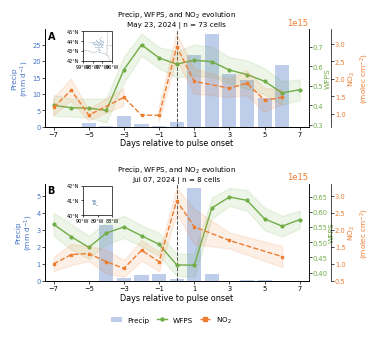

Saved.


In [25]:
# imports needed for footprint inset
from matplotlib.patches import Rectangle, Patch
from matplotlib.collections import PatchCollection
from matplotlib.lines import Line2D

#stuff
EXEMPLAR_EVENTS = [733, 1674]
WINDOW_DAYS = 7
pulse_df = groups_df.copy()

# ── Validate ──────────────────────────────────────────────────────────────────
EXEMPLAR_EVENTS = [e for e in EXEMPLAR_EVENTS if e in pulse_df["group_id"].unique()]
assert len(EXEMPLAR_EVENTS) > 0

n_events = len(EXEMPLAR_EVENTS)
panel_labels = list("ABCDEFGHIJKLMNOPQRSTUVWXYZ")

# ── Figure — PNAS one-column width ────────────────────────────────────────────
cm = 1 / 2.54
fig_w = 8.7 * cm
fig_h = 4.0 * cm * n_events

fig = plt.figure(figsize=(fig_w, fig_h))
outer = gridspec.GridSpec(n_events, 1, hspace=0.58, top=0.96, bottom=0.16, left=0.13, right=0.90)

shared_handles = None

for row, eid in enumerate(EXEMPLAR_EVENTS):

    event_pulses = pulse_df[pulse_df["group_id"] == eid].copy()
    event_cells = event_pulses[["grid_lat", "grid_lon"]].drop_duplicates()

    if event_pulses.empty:
        continue

    t0 = event_pulses["datetime"].min()

    # Soil texture
    soil_str = ""

    if "dominant_texture" in event_pulses.columns:
        es = event_pulses[["grid_lat", "grid_lon", "dominant_texture"]].drop_duplicates(subset=["grid_lat", "grid_lon"]).dropna(subset=["dominant_texture"])

        if len(es) > 0:
            vc = es["dominant_texture"].value_counts()
            soil_str = f"{vc.index[0]} ({vc.iloc[0] / vc.sum():.0%})"

    sm_label = event_pulses["sm_class"].iloc[0] if "sm_class" in event_pulses.columns else ""

    # ±7-day daily window
    sub = df.merge(event_cells, on=["grid_lat", "grid_lon"], how="inner").copy()
    sub = sub[(sub["datetime"] >= t0 - pd.Timedelta(days=WINDOW_DAYS)) & (sub["datetime"] <= t0 + pd.Timedelta(days=WINDOW_DAYS))].copy()
    sub["lag_day"] = np.floor((sub["datetime"] - t0).dt.total_seconds() / 86400.0).astype(int)

    agg_cell = {"precip": ("h_precip_mm", "sum"), "no2": ("no2_mean", "mean")}

    if "WFPS_c" in sub.columns:
        agg_cell["wfps"] = ("WFPS_c", "mean")

    cell_daily = sub.groupby(["grid_lat", "grid_lon", "lag_day"]).agg(**agg_cell).reset_index()

    agg_event = {"precip_mean": ("precip", "mean"), "precip_std": ("precip", "std"), "no2_mean": ("no2", "mean"), "no2_std": ("no2", "std")}

    if "wfps" in cell_daily.columns:
        agg_event["wfps_mean"] = ("wfps", "mean")
        agg_event["wfps_std"] = ("wfps", "std")

    event_daily = cell_daily.groupby("lag_day").agg(**agg_event).reset_index()
    full_lags = pd.DataFrame({"lag_day": np.arange(-WINDOW_DAYS, WINDOW_DAYS + 1)})
    event_daily = full_lags.merge(event_daily, on="lag_day", how="left")
    event_daily[["precip_mean", "precip_std"]] = event_daily[["precip_mean", "precip_std"]].fillna(0)

    # ── TIME SERIES MAIN PANEL ────────────────────────────────────────────────
    ax_ts = fig.add_subplot(outer[row])

    ax_ts.bar(event_daily["lag_day"], event_daily["precip_mean"], color="#4472C4", alpha=0.35, width=0.8, zorder=2)
    ax_ts.set_ylabel("Precip\n(mm d$^{-1}$)", color="#4472C4", labelpad=1, fontsize=5.3)
    ax_ts.tick_params(axis="y", labelcolor="#4472C4", labelsize=4.8, pad=1, length=2)
    ax_ts.tick_params(axis="x", labelsize=4.8, pad=1, length=2)
    ax_ts.axvline(0, color="black", linestyle="--", linewidth=0.7, alpha=0.7, zorder=3)
    ax_ts.spines[["top"]].set_visible(False)
    ax_ts.set_xlim(-WINDOW_DAYS - 0.5, WINDOW_DAYS + 0.5)
    ax_ts.set_xticks(np.arange(-WINDOW_DAYS, WINDOW_DAYS + 1, 2))
    ax_ts.set_xlabel("Days relative to pulse onset", fontsize=5.8, labelpad=1)

    has_wfps = "wfps_mean" in event_daily.columns

    if has_wfps:
        ax_wfps = ax_ts.twinx()
        vm = event_daily["wfps_mean"].notna()
        ax_wfps.plot(event_daily.loc[vm, "lag_day"], event_daily.loc[vm, "wfps_mean"], color="#70AD47", linewidth=1.0, marker="o", markersize=2.0, label="WFPS", zorder=4)
        ax_wfps.fill_between(event_daily.loc[vm, "lag_day"], (event_daily["wfps_mean"] - event_daily["wfps_std"]).loc[vm], (event_daily["wfps_mean"] + event_daily["wfps_std"]).loc[vm], color="#70AD47", alpha=0.12)
        ax_wfps.set_ylabel("WFPS", color="#70AD47", labelpad=1, fontsize=5.3)
        ax_wfps.tick_params(axis="y", labelcolor="#70AD47", labelsize=4.8, pad=1, length=2)
        ax_wfps.spines[["top"]].set_visible(False)

    ax_no2 = ax_ts.twinx()

    if has_wfps:
        ax_no2.spines["right"].set_position(("outward", 16))

    vn = event_daily["no2_mean"].notna()
    ax_no2.plot(event_daily.loc[vn, "lag_day"], event_daily.loc[vn, "no2_mean"], color="#ED7D31", linestyle="--", linewidth=1.0, marker="s", markersize=2.0, label="NO$_2$", zorder=5)
    ax_no2.fill_between(event_daily.loc[vn, "lag_day"], (event_daily["no2_mean"] - event_daily["no2_std"]).loc[vn], (event_daily["no2_mean"] + event_daily["no2_std"]).loc[vn], color="#ED7D31", alpha=0.12)
    ax_no2.set_ylabel("NO$_2$\n(molec cm$^{-2}$)", color="#ED7D31", labelpad=1, fontsize=5.3)
    ax_no2.tick_params(axis="y", labelcolor="#ED7D31", labelsize=4.8, pad=1, length=2)
    ax_no2.spines[["top"]].set_visible(False)

    # title with event/map details
    pre_precip = event_daily.loc[event_daily["lag_day"] < 0, "precip_mean"].sum()
    sm_str = f" | {sm_label}" if sm_label else ""
    soil_title = f" | {soil_str}" if soil_str else ""
    ax_ts.set_title(f"Precip, WFPS, and NO$_2$ evolution\n{t0:%b %d, %Y} | n = {len(event_cells)} cells", fontsize=5.2, pad=2)

    ax_ts.text(0.01, 0.98, panel_labels[row], transform=ax_ts.transAxes, fontsize=7, fontweight="bold", va="top", ha="left")

    # shared legend handles, only created once
    if shared_handles is None:
        shared_handles = [Patch(facecolor="#4472C4", alpha=0.35, label="Precip")]
        if has_wfps:
            shared_handles.append(Line2D([0], [0], color="#70AD47", linewidth=1.0, marker="o", markersize=2.2, label="WFPS"))
        shared_handles.append(Line2D([0], [0], color="#ED7D31", linestyle="--", linewidth=1.0, marker="s", markersize=2.2, label="NO$_2$"))

    # ── MAP INSET ─────────────────────────────────────────────────────────────
    ax_map = ax_ts.inset_axes([0.05, 0.68, 0.3, 0.3], projection=ccrs.PlateCarree())

    lon_min = event_cells["grid_lon"].min() - 0.45
    lon_max = event_cells["grid_lon"].max() + 0.45
    lat_min = event_cells["grid_lat"].min() - 0.45
    lat_max = event_cells["grid_lat"].max() + 0.45

    ax_map.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())
    ax_map.add_feature(cfeature.LAND.with_scale("50m"), facecolor="white", zorder=1)
    ax_map.add_feature(cfeature.STATES.with_scale("50m"), edgecolor="silver", linewidth=0.25, zorder=2)
    ax_map.add_feature(cfeature.BORDERS.with_scale("50m"), edgecolor="black", linewidth=0.3, zorder=3)
    ax_map.coastlines(resolution="50m", linewidth=0.25, zorder=4)

    footprint_cell_w = 0.1
    footprint_cell_h = 0.1
    rects = []

    for lon, lat in zip(event_cells["grid_lon"], event_cells["grid_lat"]):
        rects.append(Rectangle((lon - footprint_cell_w / 2, lat - footprint_cell_h / 2), footprint_cell_w, footprint_cell_h))

    pc = PatchCollection(rects, facecolor="#6E97B8", edgecolor="white", alpha=0.95, linewidth=0.2, zorder=5)
    pc.set_transform(ccrs.PlateCarree())
    ax_map.add_collection(pc)

    xticks = np.arange(np.floor(lon_min), np.ceil(lon_max) + 1, 1)
    yticks = np.arange(np.floor(lat_min), np.ceil(lat_max) + 1, 1)

    ax_map.set_xticks(xticks, crs=ccrs.PlateCarree())
    ax_map.set_yticks(yticks, crs=ccrs.PlateCarree())
    ax_map.xaxis.set_major_formatter(cticker.LongitudeFormatter())
    ax_map.yaxis.set_major_formatter(cticker.LatitudeFormatter())
    ax_map.tick_params(labelsize=3.5, pad=1, length=1.4)

# ── One shared legend at bottom ───────────────────────────────────────────────
if shared_handles is not None:
    fig.legend(handles=shared_handles, loc="lower center", bbox_to_anchor=(0.50, 0), ncol=len(shared_handles), frameon=False, fontsize=5.2, handlelength=1.4, columnspacing=1.0)

# ── Save ──────────────────────────────────────────────────────────────────────
fig.savefig("/global/home/users/toireasamarie/FINAL Paper Workflow/Paper Figures/exemplar_events_PNAS.pdf", dpi=600)
fig.savefig("/global/home/users/toireasamarie/FINAL Paper Workflow/Paper Figures/exemplar_events_PNAS.png", dpi=300)
plt.show()

print("Saved.")

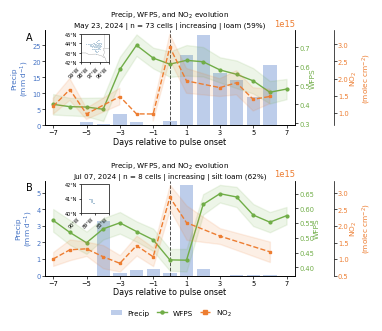

Saved.


In [29]:
# imports needed for footprint inset
from matplotlib.patches import Rectangle, Patch
from matplotlib.collections import PatchCollection
from matplotlib.lines import Line2D

#stuff
EXEMPLAR_EVENTS = [733, 1674]
WINDOW_DAYS = 7
pulse_df = groups_df.copy()

# ── Validate ──────────────────────────────────────────────────────────────────
EXEMPLAR_EVENTS = [e for e in EXEMPLAR_EVENTS if e in pulse_df["group_id"].unique()]
assert len(EXEMPLAR_EVENTS) > 0

n_events = len(EXEMPLAR_EVENTS)
panel_labels = list("ABCDEFGHIJKLMNOPQRSTUVWXYZ")

# ── Figure — PNAS one-column width ────────────────────────────────────────────
cm = 1 / 2.54
fig_w = 8.7 * cm
fig_h = 4.0 * cm * n_events

fig = plt.figure(figsize=(fig_w, fig_h))
outer = gridspec.GridSpec(n_events, 1, hspace=0.58, top=0.96, bottom=0.18, left=0.13, right=0.86)

shared_handles = None
ts_axes = []

for row, eid in enumerate(EXEMPLAR_EVENTS):

    event_pulses = pulse_df[pulse_df["group_id"] == eid].copy()
    event_cells = event_pulses[["grid_lat", "grid_lon"]].drop_duplicates()

    if event_pulses.empty:
        continue

    t0 = event_pulses["datetime"].min()

    # Soil texture
    soil_str = ""

    if "dominant_texture" in event_pulses.columns:
        es = event_pulses[["grid_lat", "grid_lon", "dominant_texture"]].drop_duplicates(subset=["grid_lat", "grid_lon"]).dropna(subset=["dominant_texture"])

        if len(es) > 0:
            vc = es["dominant_texture"].value_counts()
            soil_str = f"{vc.index[0]} ({vc.iloc[0] / vc.sum():.0%})"

    sm_label = event_pulses["sm_class"].iloc[0] if "sm_class" in event_pulses.columns else ""

    # ±7-day daily window
    sub = df.merge(event_cells, on=["grid_lat", "grid_lon"], how="inner").copy()
    sub = sub[(sub["datetime"] >= t0 - pd.Timedelta(days=WINDOW_DAYS)) & (sub["datetime"] <= t0 + pd.Timedelta(days=WINDOW_DAYS))].copy()
    sub["lag_day"] = np.floor((sub["datetime"] - t0).dt.total_seconds() / 86400.0).astype(int)

    agg_cell = {"precip": ("h_precip_mm", "sum"), "no2": ("no2_mean", "mean")}

    if "WFPS_c" in sub.columns:
        agg_cell["wfps"] = ("WFPS_c", "mean")

    cell_daily = sub.groupby(["grid_lat", "grid_lon", "lag_day"]).agg(**agg_cell).reset_index()

    agg_event = {"precip_mean": ("precip", "mean"), "precip_std": ("precip", "std"), "no2_mean": ("no2", "mean"), "no2_std": ("no2", "std")}

    if "wfps" in cell_daily.columns:
        agg_event["wfps_mean"] = ("wfps", "mean")
        agg_event["wfps_std"] = ("wfps", "std")

    event_daily = cell_daily.groupby("lag_day").agg(**agg_event).reset_index()
    full_lags = pd.DataFrame({"lag_day": np.arange(-WINDOW_DAYS, WINDOW_DAYS + 1)})
    event_daily = full_lags.merge(event_daily, on="lag_day", how="left")
    event_daily[["precip_mean", "precip_std"]] = event_daily[["precip_mean", "precip_std"]].fillna(0)

    # ── TIME SERIES MAIN PANEL ────────────────────────────────────────────────
    ax_ts = fig.add_subplot(outer[row])
    ts_axes.append(ax_ts)

    ax_ts.bar(event_daily["lag_day"], event_daily["precip_mean"], color="#4472C4", alpha=0.35, width=0.8, zorder=2)
    ax_ts.set_ylabel("Precip\n(mm d$^{-1}$)", color="#4472C4", labelpad=1, fontsize=5.3)
    ax_ts.tick_params(axis="y", labelcolor="#4472C4", labelsize=4.8, pad=1, length=2)
    ax_ts.tick_params(axis="x", labelsize=4.8, pad=1, length=2)
    ax_ts.axvline(0, color="black", linestyle="--", linewidth=0.7, alpha=0.7, zorder=3)
    ax_ts.spines[["top"]].set_visible(False)
    ax_ts.set_xlim(-WINDOW_DAYS - 0.5, WINDOW_DAYS + 0.5)
    ax_ts.set_xticks(np.arange(-WINDOW_DAYS, WINDOW_DAYS + 1, 2))
    ax_ts.set_xlabel("Days relative to pulse onset", fontsize=5.8, labelpad=1)

    has_wfps = "wfps_mean" in event_daily.columns

    if has_wfps:
        ax_wfps = ax_ts.twinx()
        vm = event_daily["wfps_mean"].notna()
        ax_wfps.plot(event_daily.loc[vm, "lag_day"], event_daily.loc[vm, "wfps_mean"], color="#70AD47", linewidth=1.0, marker="o", markersize=2.0, label="WFPS", zorder=4)
        ax_wfps.fill_between(event_daily.loc[vm, "lag_day"], (event_daily["wfps_mean"] - event_daily["wfps_std"]).loc[vm], (event_daily["wfps_mean"] + event_daily["wfps_std"]).loc[vm], color="#70AD47", alpha=0.12)
        ax_wfps.set_ylabel("WFPS", color="#70AD47", labelpad=0, fontsize=5.3)
        ax_wfps.tick_params(axis="y", labelcolor="#70AD47", labelsize=4.8, pad=1, length=2)
        ax_wfps.spines[["top"]].set_visible(False)

    ax_no2 = ax_ts.twinx()

    if has_wfps:
        ax_no2.spines["right"].set_position(("outward", 28))

    vn = event_daily["no2_mean"].notna()
    ax_no2.plot(event_daily.loc[vn, "lag_day"], event_daily.loc[vn, "no2_mean"], color="#ED7D31", linestyle="--", linewidth=1.0, marker="s", markersize=2.0, label="NO$_2$", zorder=5)
    ax_no2.fill_between(event_daily.loc[vn, "lag_day"], (event_daily["no2_mean"] - event_daily["no2_std"]).loc[vn], (event_daily["no2_mean"] + event_daily["no2_std"]).loc[vn], color="#ED7D31", alpha=0.12)
    ax_no2.set_ylabel("NO$_2$\n(molec cm$^{-2}$)", color="#ED7D31", labelpad=0, fontsize=5.3)
    ax_no2.tick_params(axis="y", labelcolor="#ED7D31", labelsize=4.8, pad=1, length=2)
    ax_no2.spines[["top"]].set_visible(False)

    # title with event/map details
    pre_precip = event_daily.loc[event_daily["lag_day"] < 0, "precip_mean"].sum()
    sm_str = f" | {sm_label}" if sm_label else ""
    soil_title = f" | {soil_str}" if soil_str else ""
    ax_ts.set_title(f"Precip, WFPS, and NO$_2$ evolution\n{t0:%b %d, %Y} | n = {len(event_cells)} cells{sm_str}{soil_title}", fontsize=5.2, pad=2)

    # shared legend handles, only created once
    if shared_handles is None:
        shared_handles = [Patch(facecolor="#4472C4", alpha=0.35, label="Precip")]
        if has_wfps:
            shared_handles.append(Line2D([0], [0], color="#70AD47", linewidth=1.0, marker="o", markersize=2.2, label="WFPS"))
        shared_handles.append(Line2D([0], [0], color="#ED7D31", linestyle="--", linewidth=1.0, marker="s", markersize=2.2, label="NO$_2$"))

    # ── MAP INSET ─────────────────────────────────────────────────────────────
    ax_map = ax_ts.inset_axes([0.05, 0.66, 0.3, 0.3], projection=ccrs.PlateCarree())

    lon_min = event_cells["grid_lon"].min() - 0.45
    lon_max = event_cells["grid_lon"].max() + 0.45
    lat_min = event_cells["grid_lat"].min() - 0.45
    lat_max = event_cells["grid_lat"].max() + 0.45

    ax_map.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())
    ax_map.add_feature(cfeature.LAND.with_scale("50m"), facecolor="white", zorder=1)
    ax_map.add_feature(cfeature.STATES.with_scale("50m"), edgecolor="silver", linewidth=0.25, zorder=2)
    ax_map.add_feature(cfeature.BORDERS.with_scale("50m"), edgecolor="black", linewidth=0.3, zorder=3)
    ax_map.coastlines(resolution="50m", linewidth=0.25, zorder=4)

    footprint_cell_w = 0.1
    footprint_cell_h = 0.1
    rects = []

    for lon, lat in zip(event_cells["grid_lon"], event_cells["grid_lat"]):
        rects.append(Rectangle((lon - footprint_cell_w / 2, lat - footprint_cell_h / 2), footprint_cell_w, footprint_cell_h))

    pc = PatchCollection(rects, facecolor="#6E97B8", edgecolor="white", alpha=0.95, linewidth=0.2, zorder=5)
    pc.set_transform(ccrs.PlateCarree())
    ax_map.add_collection(pc)

    xticks = np.arange(np.floor(lon_min), np.ceil(lon_max) + 1, 1)
    yticks = np.arange(np.floor(lat_min), np.ceil(lat_max) + 1, 1)

    ax_map.set_xticks(xticks, crs=ccrs.PlateCarree())
    ax_map.set_yticks(yticks, crs=ccrs.PlateCarree())
    ax_map.xaxis.set_major_formatter(cticker.LongitudeFormatter())
    ax_map.yaxis.set_major_formatter(cticker.LatitudeFormatter())

    for label in ax_map.get_xticklabels():
        label.set_rotation(45)
        label.set_ha("right")

    ax_map.tick_params(labelsize=3.5, pad=1, length=1.4)

# ── Panel labels outside axes ─────────────────────────────────────────────────
fig.canvas.draw()

for ax, label in zip(ts_axes, panel_labels[:len(ts_axes)]):
    pos = ax.get_position()
    fig.text(pos.x0 - 0.055, pos.y1 - 0.005, label, ha="left", va="top", fontsize=7)

# ── One shared legend at bottom ───────────────────────────────────────────────
if shared_handles is not None:
    fig.legend(handles=shared_handles, loc="lower center", bbox_to_anchor=(0.50, 0.025), ncol=len(shared_handles), frameon=False, fontsize=5.2, handlelength=1.4, columnspacing=1.0)

# ── Save ──────────────────────────────────────────────────────────────────────
fig.savefig("/global/home/users/toireasamarie/FINAL Paper Workflow/Paper Figures/exemplar_events_PNAS.pdf", dpi=600, bbox_inches="tight", pad_inches=0.03)
fig.savefig("/global/home/users/toireasamarie/FINAL Paper Workflow/Paper Figures/exemplar_events_PNAS.png", dpi=300, bbox_inches="tight", pad_inches=0.03)
plt.show()

print("Saved.")

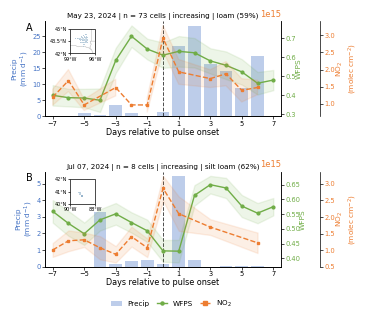

Saved.


In [30]:
# imports needed for footprint inset
from matplotlib.patches import Rectangle, Patch
from matplotlib.collections import PatchCollection
from matplotlib.lines import Line2D

#stuff
EXEMPLAR_EVENTS = [733, 1674]
WINDOW_DAYS = 7
pulse_df = groups_df.copy()

# ── Validate ──────────────────────────────────────────────────────────────────
EXEMPLAR_EVENTS = [e for e in EXEMPLAR_EVENTS if e in pulse_df["group_id"].unique()]
assert len(EXEMPLAR_EVENTS) > 0

n_events = len(EXEMPLAR_EVENTS)
panel_labels = list("ABCDEFGHIJKLMNOPQRSTUVWXYZ")

# ── Figure — PNAS one-column width ────────────────────────────────────────────
cm = 1 / 2.54
fig_w = 8.7 * cm
fig_h = 4.0 * cm * n_events

fig = plt.figure(figsize=(fig_w, fig_h))
outer = gridspec.GridSpec(n_events, 1, hspace=0.58, top=0.96, bottom=0.18, left=0.13, right=0.82)

shared_handles = None
ts_axes = []

for row, eid in enumerate(EXEMPLAR_EVENTS):

    event_pulses = pulse_df[pulse_df["group_id"] == eid].copy()
    event_cells = event_pulses[["grid_lat", "grid_lon"]].drop_duplicates()

    if event_pulses.empty:
        continue

    t0 = event_pulses["datetime"].min()

    # Soil texture
    soil_str = ""

    if "dominant_texture" in event_pulses.columns:
        es = event_pulses[["grid_lat", "grid_lon", "dominant_texture"]].drop_duplicates(subset=["grid_lat", "grid_lon"]).dropna(subset=["dominant_texture"])

        if len(es) > 0:
            vc = es["dominant_texture"].value_counts()
            soil_str = f"{vc.index[0]} ({vc.iloc[0] / vc.sum():.0%})"

    sm_label = event_pulses["sm_class"].iloc[0] if "sm_class" in event_pulses.columns else ""

    # ±7-day daily window
    sub = df.merge(event_cells, on=["grid_lat", "grid_lon"], how="inner").copy()
    sub = sub[(sub["datetime"] >= t0 - pd.Timedelta(days=WINDOW_DAYS)) & (sub["datetime"] <= t0 + pd.Timedelta(days=WINDOW_DAYS))].copy()
    sub["lag_day"] = np.floor((sub["datetime"] - t0).dt.total_seconds() / 86400.0).astype(int)

    agg_cell = {"precip": ("h_precip_mm", "sum"), "no2": ("no2_mean", "mean")}

    if "WFPS_c" in sub.columns:
        agg_cell["wfps"] = ("WFPS_c", "mean")

    cell_daily = sub.groupby(["grid_lat", "grid_lon", "lag_day"]).agg(**agg_cell).reset_index()

    agg_event = {"precip_mean": ("precip", "mean"), "precip_std": ("precip", "std"), "no2_mean": ("no2", "mean"), "no2_std": ("no2", "std")}

    if "wfps" in cell_daily.columns:
        agg_event["wfps_mean"] = ("wfps", "mean")
        agg_event["wfps_std"] = ("wfps", "std")

    event_daily = cell_daily.groupby("lag_day").agg(**agg_event).reset_index()
    full_lags = pd.DataFrame({"lag_day": np.arange(-WINDOW_DAYS, WINDOW_DAYS + 1)})
    event_daily = full_lags.merge(event_daily, on="lag_day", how="left")
    event_daily[["precip_mean", "precip_std"]] = event_daily[["precip_mean", "precip_std"]].fillna(0)

    # ── TIME SERIES MAIN PANEL ────────────────────────────────────────────────
    ax_ts = fig.add_subplot(outer[row])
    ts_axes.append(ax_ts)

    ax_ts.bar(event_daily["lag_day"], event_daily["precip_mean"], color="#4472C4", alpha=0.35, width=0.8, zorder=2)
    ax_ts.set_ylabel("Precip\n(mm d$^{-1}$)", color="#4472C4", labelpad=1, fontsize=5.3)
    ax_ts.tick_params(axis="y", labelcolor="#4472C4", labelsize=4.8, pad=1, length=2)
    ax_ts.tick_params(axis="x", labelsize=4.8, pad=1, length=2)
    ax_ts.axvline(0, color="black", linestyle="--", linewidth=0.7, alpha=0.7, zorder=3)
    ax_ts.spines[["top"]].set_visible(False)
    ax_ts.set_xlim(-WINDOW_DAYS - 0.5, WINDOW_DAYS + 0.5)
    ax_ts.set_xticks(np.arange(-WINDOW_DAYS, WINDOW_DAYS + 1, 2))
    ax_ts.set_xlabel("Days relative to pulse onset", fontsize=5.8, labelpad=1)

    has_wfps = "wfps_mean" in event_daily.columns

    if has_wfps:
        ax_wfps = ax_ts.twinx()
        vm = event_daily["wfps_mean"].notna()
        ax_wfps.plot(event_daily.loc[vm, "lag_day"], event_daily.loc[vm, "wfps_mean"], color="#70AD47", linewidth=1.0, marker="o", markersize=2.0, label="WFPS", zorder=4)
        ax_wfps.fill_between(event_daily.loc[vm, "lag_day"], (event_daily["wfps_mean"] - event_daily["wfps_std"]).loc[vm], (event_daily["wfps_mean"] + event_daily["wfps_std"]).loc[vm], color="#70AD47", alpha=0.12)
        ax_wfps.set_ylabel("WFPS", color="#70AD47", labelpad=0, fontsize=5.3)
        ax_wfps.tick_params(axis="y", labelcolor="#70AD47", labelsize=4.8, pad=1, length=2)
        ax_wfps.spines[["top"]].set_visible(False)

    ax_no2 = ax_ts.twinx()

    if has_wfps:
        ax_no2.spines["right"].set_position(("outward", 28))

    vn = event_daily["no2_mean"].notna()
    ax_no2.plot(event_daily.loc[vn, "lag_day"], event_daily.loc[vn, "no2_mean"], color="#ED7D31", linestyle="--", linewidth=1.0, marker="s", markersize=2.0, label="NO$_2$", zorder=5)
    ax_no2.fill_between(event_daily.loc[vn, "lag_day"], (event_daily["no2_mean"] - event_daily["no2_std"]).loc[vn], (event_daily["no2_mean"] + event_daily["no2_std"]).loc[vn], color="#ED7D31", alpha=0.12)
    ax_no2.set_ylabel("NO$_2$\n(molec cm$^{-2}$)", color="#ED7D31", labelpad=0, fontsize=5.3)
    ax_no2.tick_params(axis="y", labelcolor="#ED7D31", labelsize=4.8, pad=1, length=2)
    ax_no2.spines[["top"]].set_visible(False)

    # title with event/map details
    pre_precip = event_daily.loc[event_daily["lag_day"] < 0, "precip_mean"].sum()
    sm_str = f" | {sm_label}" if sm_label else ""
    soil_title = f" | {soil_str}" if soil_str else ""
    ax_ts.set_title(f"{t0:%b %d, %Y} | n = {len(event_cells)} cells{sm_str}{soil_title}", fontsize=5.2, pad=2)

    # shared legend handles, only created once
    if shared_handles is None:
        shared_handles = [Patch(facecolor="#4472C4", alpha=0.35, label="Precip")]
        if has_wfps:
            shared_handles.append(Line2D([0], [0], color="#70AD47", linewidth=1.0, marker="o", markersize=2.2, label="WFPS"))
        shared_handles.append(Line2D([0], [0], color="#ED7D31", linestyle="--", linewidth=1.0, marker="s", markersize=2.2, label="NO$_2$"))

    # ── MAP INSET ─────────────────────────────────────────────────────────────
    ax_map = ax_ts.inset_axes([0.05, 0.66, 0.22, 0.26], projection=ccrs.PlateCarree())

    lon_min = event_cells["grid_lon"].min() - 0.45
    lon_max = event_cells["grid_lon"].max() + 0.45
    lat_min = event_cells["grid_lat"].min() - 0.45
    lat_max = event_cells["grid_lat"].max() + 0.45

    ax_map.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())
    ax_map.add_feature(cfeature.LAND.with_scale("50m"), facecolor="white", zorder=1)
    ax_map.add_feature(cfeature.STATES.with_scale("50m"), edgecolor="silver", linewidth=0.25, zorder=2)
    ax_map.add_feature(cfeature.BORDERS.with_scale("50m"), edgecolor="black", linewidth=0.3, zorder=3)
    ax_map.coastlines(resolution="50m", linewidth=0.25, zorder=4)

    footprint_cell_w = 0.1
    footprint_cell_h = 0.1
    rects = []

    for lon, lat in zip(event_cells["grid_lon"], event_cells["grid_lat"]):
        rects.append(Rectangle((lon - footprint_cell_w / 2, lat - footprint_cell_h / 2), footprint_cell_w, footprint_cell_h))

    pc = PatchCollection(rects, facecolor="#6E97B8", edgecolor="white", alpha=0.95, linewidth=0.2, zorder=5)
    pc.set_transform(ccrs.PlateCarree())
    ax_map.add_collection(pc)

    # fewer ticks for small inset
    xticks = np.linspace(np.floor(lon_min), np.ceil(lon_max), 2)
    yticks = np.linspace(np.floor(lat_min), np.ceil(lat_max), 3)

    ax_map.set_xticks(xticks, crs=ccrs.PlateCarree())
    ax_map.set_yticks(yticks, crs=ccrs.PlateCarree())
    ax_map.xaxis.set_major_formatter(cticker.LongitudeFormatter())
    ax_map.yaxis.set_major_formatter(cticker.LatitudeFormatter())
    ax_map.tick_params(labelsize=3.5, pad=1, length=1.4)

# ── Panel labels outside axes ─────────────────────────────────────────────────
fig.canvas.draw()

for ax, label in zip(ts_axes, panel_labels[:len(ts_axes)]):
    pos = ax.get_position()
    fig.text(pos.x0 - 0.055, pos.y1 - 0.005, label, ha="left", va="top", fontsize=7)

# ── One shared legend at bottom ───────────────────────────────────────────────
if shared_handles is not None:
    fig.legend(handles=shared_handles, loc="lower center", bbox_to_anchor=(0.50, 0.025), ncol=len(shared_handles), frameon=False, fontsize=5.2, handlelength=1.4, columnspacing=1.0)

# ── Save ──────────────────────────────────────────────────────────────────────
fig.savefig("/global/home/users/toireasamarie/FINAL Paper Workflow/Paper Figures/exemplar_events_PNAS.pdf", dpi=600, bbox_inches="tight", pad_inches=0.03)
fig.savefig("/global/home/users/toireasamarie/FINAL Paper Workflow/Paper Figures/exemplar_events_PNAS.png", dpi=300, bbox_inches="tight", pad_inches=0.03)
plt.show()

print("Saved.")

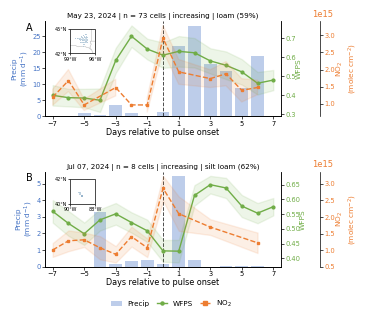

Saved.


In [31]:
# imports needed for footprint inset
from matplotlib.patches import Rectangle, Patch
from matplotlib.collections import PatchCollection
from matplotlib.lines import Line2D

#stuff
EXEMPLAR_EVENTS = [733, 1674]
WINDOW_DAYS = 7
pulse_df = groups_df.copy()

# ── Validate ──────────────────────────────────────────────────────────────────
EXEMPLAR_EVENTS = [e for e in EXEMPLAR_EVENTS if e in pulse_df["group_id"].unique()]
assert len(EXEMPLAR_EVENTS) > 0

n_events = len(EXEMPLAR_EVENTS)
panel_labels = list("ABCDEFGHIJKLMNOPQRSTUVWXYZ")

# ── Figure — PNAS one-column width ────────────────────────────────────────────
cm = 1 / 2.54
fig_w = 8.7 * cm
fig_h = 4.0 * cm * n_events

fig = plt.figure(figsize=(fig_w, fig_h))
outer = gridspec.GridSpec(n_events, 1, hspace=0.58, top=0.96, bottom=0.18, left=0.13, right=0.82)

shared_handles = None
ts_axes = []

for row, eid in enumerate(EXEMPLAR_EVENTS):

    event_pulses = pulse_df[pulse_df["group_id"] == eid].copy()
    event_cells = event_pulses[["grid_lat", "grid_lon"]].drop_duplicates()

    if event_pulses.empty:
        continue

    t0 = event_pulses["datetime"].min()

    # Soil texture
    soil_str = ""

    if "dominant_texture" in event_pulses.columns:
        es = event_pulses[["grid_lat", "grid_lon", "dominant_texture"]].drop_duplicates(subset=["grid_lat", "grid_lon"]).dropna(subset=["dominant_texture"])

        if len(es) > 0:
            vc = es["dominant_texture"].value_counts()
            soil_str = f"{vc.index[0]} ({vc.iloc[0] / vc.sum():.0%})"

    sm_label = event_pulses["sm_class"].iloc[0] if "sm_class" in event_pulses.columns else ""

    # ±7-day daily window
    sub = df.merge(event_cells, on=["grid_lat", "grid_lon"], how="inner").copy()
    sub = sub[(sub["datetime"] >= t0 - pd.Timedelta(days=WINDOW_DAYS)) & (sub["datetime"] <= t0 + pd.Timedelta(days=WINDOW_DAYS))].copy()
    sub["lag_day"] = np.floor((sub["datetime"] - t0).dt.total_seconds() / 86400.0).astype(int)

    agg_cell = {"precip": ("h_precip_mm", "sum"), "no2": ("no2_mean", "mean")}

    if "WFPS_c" in sub.columns:
        agg_cell["wfps"] = ("WFPS_c", "mean")

    cell_daily = sub.groupby(["grid_lat", "grid_lon", "lag_day"]).agg(**agg_cell).reset_index()

    agg_event = {"precip_mean": ("precip", "mean"), "precip_std": ("precip", "std"), "no2_mean": ("no2", "mean"), "no2_std": ("no2", "std")}

    if "wfps" in cell_daily.columns:
        agg_event["wfps_mean"] = ("wfps", "mean")
        agg_event["wfps_std"] = ("wfps", "std")

    event_daily = cell_daily.groupby("lag_day").agg(**agg_event).reset_index()
    full_lags = pd.DataFrame({"lag_day": np.arange(-WINDOW_DAYS, WINDOW_DAYS + 1)})
    event_daily = full_lags.merge(event_daily, on="lag_day", how="left")
    event_daily[["precip_mean", "precip_std"]] = event_daily[["precip_mean", "precip_std"]].fillna(0)

    # ── TIME SERIES MAIN PANEL ────────────────────────────────────────────────
    ax_ts = fig.add_subplot(outer[row])
    ts_axes.append(ax_ts)

    ax_ts.bar(event_daily["lag_day"], event_daily["precip_mean"], color="#4472C4", alpha=0.35, width=0.8, zorder=2)
    ax_ts.set_ylabel("Precip\n(mm d$^{-1}$)", color="#4472C4", labelpad=1, fontsize=5.3)
    ax_ts.tick_params(axis="y", labelcolor="#4472C4", labelsize=4.8, pad=1, length=2)
    ax_ts.tick_params(axis="x", labelsize=4.8, pad=1, length=2)
    ax_ts.axvline(0, color="black", linestyle="--", linewidth=0.7, alpha=0.7, zorder=3)
    ax_ts.spines[["top"]].set_visible(False)
    ax_ts.set_xlim(-WINDOW_DAYS - 0.5, WINDOW_DAYS + 0.5)
    ax_ts.set_xticks(np.arange(-WINDOW_DAYS, WINDOW_DAYS + 1, 2))
    ax_ts.set_xlabel("Days relative to pulse onset", fontsize=5.8, labelpad=1)

    has_wfps = "wfps_mean" in event_daily.columns

    if has_wfps:
        ax_wfps = ax_ts.twinx()
        vm = event_daily["wfps_mean"].notna()
        ax_wfps.plot(event_daily.loc[vm, "lag_day"], event_daily.loc[vm, "wfps_mean"], color="#70AD47", linewidth=1.0, marker="o", markersize=2.0, label="WFPS", zorder=4)
        ax_wfps.fill_between(event_daily.loc[vm, "lag_day"], (event_daily["wfps_mean"] - event_daily["wfps_std"]).loc[vm], (event_daily["wfps_mean"] + event_daily["wfps_std"]).loc[vm], color="#70AD47", alpha=0.12)
        ax_wfps.set_ylabel("WFPS", color="#70AD47", labelpad=0, fontsize=5.3)
        ax_wfps.tick_params(axis="y", labelcolor="#70AD47", labelsize=4.8, pad=1, length=2)
        ax_wfps.spines[["top"]].set_visible(False)

    ax_no2 = ax_ts.twinx()

    if has_wfps:
        ax_no2.spines["right"].set_position(("outward", 28))

    vn = event_daily["no2_mean"].notna()
    ax_no2.plot(event_daily.loc[vn, "lag_day"], event_daily.loc[vn, "no2_mean"], color="#ED7D31", linestyle="--", linewidth=1.0, marker="s", markersize=2.0, label="NO$_2$", zorder=5)
    ax_no2.fill_between(event_daily.loc[vn, "lag_day"], (event_daily["no2_mean"] - event_daily["no2_std"]).loc[vn], (event_daily["no2_mean"] + event_daily["no2_std"]).loc[vn], color="#ED7D31", alpha=0.12)
    ax_no2.set_ylabel("NO$_2$\n(molec cm$^{-2}$)", color="#ED7D31", labelpad=0, fontsize=5.3)
    ax_no2.tick_params(axis="y", labelcolor="#ED7D31", labelsize=4.8, pad=1, length=2)
    ax_no2.spines[["top"]].set_visible(False)

    # move NO2 scientific notation over outer right axis
    ax_no2.yaxis.get_offset_text().set_x(1.22)
    ax_no2.yaxis.get_offset_text().set_y(1.02)
    ax_no2.yaxis.get_offset_text().set_color("#ED7D31")

    # title with event/map details
    pre_precip = event_daily.loc[event_daily["lag_day"] < 0, "precip_mean"].sum()
    sm_str = f" | {sm_label}" if sm_label else ""
    soil_title = f" | {soil_str}" if soil_str else ""
    ax_ts.set_title(f"{t0:%b %d, %Y} | n = {len(event_cells)} cells{sm_str}{soil_title}", fontsize=5.2, pad=2)

    # shared legend handles, only created once
    if shared_handles is None:
        shared_handles = [Patch(facecolor="#4472C4", alpha=0.35, label="Precip")]
        if has_wfps:
            shared_handles.append(Line2D([0], [0], color="#70AD47", linewidth=1.0, marker="o", markersize=2.2, label="WFPS"))
        shared_handles.append(Line2D([0], [0], color="#ED7D31", linestyle="--", linewidth=1.0, marker="s", markersize=2.2, label="NO$_2$"))

    # ── MAP INSET ─────────────────────────────────────────────────────────────
    ax_map = ax_ts.inset_axes([0.05, 0.66, 0.22, 0.26], projection=ccrs.PlateCarree())

    lon_min = event_cells["grid_lon"].min() - 0.45
    lon_max = event_cells["grid_lon"].max() + 0.45
    lat_min = event_cells["grid_lat"].min() - 0.45
    lat_max = event_cells["grid_lat"].max() + 0.45

    ax_map.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())
    ax_map.add_feature(cfeature.LAND.with_scale("50m"), facecolor="white", zorder=1)
    ax_map.add_feature(cfeature.STATES.with_scale("50m"), edgecolor="silver", linewidth=0.25, zorder=2)
    ax_map.add_feature(cfeature.BORDERS.with_scale("50m"), edgecolor="black", linewidth=0.3, zorder=3)
    ax_map.coastlines(resolution="50m", linewidth=0.25, zorder=4)

    footprint_cell_w = 0.1
    footprint_cell_h = 0.1
    rects = []

    for lon, lat in zip(event_cells["grid_lon"], event_cells["grid_lat"]):
        rects.append(Rectangle((lon - footprint_cell_w / 2, lat - footprint_cell_h / 2), footprint_cell_w, footprint_cell_h))

    pc = PatchCollection(rects, facecolor="#6E97B8", edgecolor="white", alpha=0.95, linewidth=0.2, zorder=5)
    pc.set_transform(ccrs.PlateCarree())
    ax_map.add_collection(pc)

    # fewer ticks for small inset
    xticks = np.linspace(np.floor(lon_min), np.ceil(lon_max), 2)
    yticks = np.linspace(np.floor(lat_min), np.ceil(lat_max), 2)

    ax_map.set_xticks(xticks, crs=ccrs.PlateCarree())
    ax_map.set_yticks(yticks, crs=ccrs.PlateCarree())
    ax_map.xaxis.set_major_formatter(cticker.LongitudeFormatter())
    ax_map.yaxis.set_major_formatter(cticker.LatitudeFormatter())
    ax_map.tick_params(labelsize=3.5, pad=1, length=1.4)

# ── Panel labels outside axes ─────────────────────────────────────────────────
fig.canvas.draw()

for ax, label in zip(ts_axes, panel_labels[:len(ts_axes)]):
    pos = ax.get_position()
    fig.text(pos.x0 - 0.055, pos.y1 - 0.005, label, ha="left", va="top", fontsize=7)

# ── One shared legend at bottom ───────────────────────────────────────────────
if shared_handles is not None:
    fig.legend(handles=shared_handles, loc="lower center", bbox_to_anchor=(0.50, 0.025), ncol=len(shared_handles), frameon=False, fontsize=5.2, handlelength=1.4, columnspacing=1.0)

# ── Save ──────────────────────────────────────────────────────────────────────
fig.savefig("/global/home/users/toireasamarie/FINAL Paper Workflow/Paper Figures/exemplar_events_PNAS.pdf", dpi=600, bbox_inches="tight", pad_inches=0.03)
fig.savefig("/global/home/users/toireasamarie/FINAL Paper Workflow/Paper Figures/exemplar_events_PNAS.png", dpi=300, bbox_inches="tight", pad_inches=0.03)
plt.show()

print("Saved.")

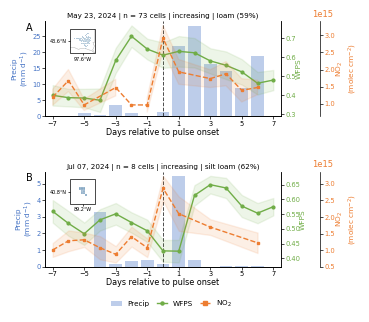

Saved.


In [32]:
# imports needed for footprint inset
from matplotlib.patches import Rectangle, Patch
from matplotlib.collections import PatchCollection
from matplotlib.lines import Line2D

#stuff
EXEMPLAR_EVENTS = [733, 1674]
WINDOW_DAYS = 7
pulse_df = groups_df.copy()

# ── Validate ──────────────────────────────────────────────────────────────────
EXEMPLAR_EVENTS = [e for e in EXEMPLAR_EVENTS if e in pulse_df["group_id"].unique()]
assert len(EXEMPLAR_EVENTS) > 0

n_events = len(EXEMPLAR_EVENTS)
panel_labels = list("ABCDEFGHIJKLMNOPQRSTUVWXYZ")

# ── Figure — PNAS one-column width ────────────────────────────────────────────
cm = 1 / 2.54
fig_w = 8.7 * cm
fig_h = 4.0 * cm * n_events

fig = plt.figure(figsize=(fig_w, fig_h))
outer = gridspec.GridSpec(n_events, 1, hspace=0.58, top=0.96, bottom=0.18, left=0.13, right=0.82)

shared_handles = None
ts_axes = []

for row, eid in enumerate(EXEMPLAR_EVENTS):

    event_pulses = pulse_df[pulse_df["group_id"] == eid].copy()
    event_cells = event_pulses[["grid_lat", "grid_lon"]].drop_duplicates()

    if event_pulses.empty:
        continue

    t0 = event_pulses["datetime"].min()

    # Soil texture
    soil_str = ""

    if "dominant_texture" in event_pulses.columns:
        es = event_pulses[["grid_lat", "grid_lon", "dominant_texture"]].drop_duplicates(subset=["grid_lat", "grid_lon"]).dropna(subset=["dominant_texture"])

        if len(es) > 0:
            vc = es["dominant_texture"].value_counts()
            soil_str = f"{vc.index[0]} ({vc.iloc[0] / vc.sum():.0%})"

    sm_label = event_pulses["sm_class"].iloc[0] if "sm_class" in event_pulses.columns else ""

    # ±7-day daily window
    sub = df.merge(event_cells, on=["grid_lat", "grid_lon"], how="inner").copy()
    sub = sub[(sub["datetime"] >= t0 - pd.Timedelta(days=WINDOW_DAYS)) & (sub["datetime"] <= t0 + pd.Timedelta(days=WINDOW_DAYS))].copy()
    sub["lag_day"] = np.floor((sub["datetime"] - t0).dt.total_seconds() / 86400.0).astype(int)

    agg_cell = {"precip": ("h_precip_mm", "sum"), "no2": ("no2_mean", "mean")}

    if "WFPS_c" in sub.columns:
        agg_cell["wfps"] = ("WFPS_c", "mean")

    cell_daily = sub.groupby(["grid_lat", "grid_lon", "lag_day"]).agg(**agg_cell).reset_index()

    agg_event = {"precip_mean": ("precip", "mean"), "precip_std": ("precip", "std"), "no2_mean": ("no2", "mean"), "no2_std": ("no2", "std")}

    if "wfps" in cell_daily.columns:
        agg_event["wfps_mean"] = ("wfps", "mean")
        agg_event["wfps_std"] = ("wfps", "std")

    event_daily = cell_daily.groupby("lag_day").agg(**agg_event).reset_index()
    full_lags = pd.DataFrame({"lag_day": np.arange(-WINDOW_DAYS, WINDOW_DAYS + 1)})
    event_daily = full_lags.merge(event_daily, on="lag_day", how="left")
    event_daily[["precip_mean", "precip_std"]] = event_daily[["precip_mean", "precip_std"]].fillna(0)

    # ── TIME SERIES MAIN PANEL ────────────────────────────────────────────────
    ax_ts = fig.add_subplot(outer[row])
    ts_axes.append(ax_ts)

    ax_ts.bar(event_daily["lag_day"], event_daily["precip_mean"], color="#4472C4", alpha=0.35, width=0.8, zorder=2)
    ax_ts.set_ylabel("Precip\n(mm d$^{-1}$)", color="#4472C4", labelpad=1, fontsize=5.3)
    ax_ts.tick_params(axis="y", labelcolor="#4472C4", labelsize=4.8, pad=1, length=2)
    ax_ts.tick_params(axis="x", labelsize=4.8, pad=1, length=2)
    ax_ts.axvline(0, color="black", linestyle="--", linewidth=0.7, alpha=0.7, zorder=3)
    ax_ts.spines[["top"]].set_visible(False)
    ax_ts.set_xlim(-WINDOW_DAYS - 0.5, WINDOW_DAYS + 0.5)
    ax_ts.set_xticks(np.arange(-WINDOW_DAYS, WINDOW_DAYS + 1, 2))
    ax_ts.set_xlabel("Days relative to pulse onset", fontsize=5.8, labelpad=1)

    has_wfps = "wfps_mean" in event_daily.columns

    if has_wfps:
        ax_wfps = ax_ts.twinx()
        vm = event_daily["wfps_mean"].notna()
        ax_wfps.plot(event_daily.loc[vm, "lag_day"], event_daily.loc[vm, "wfps_mean"], color="#70AD47", linewidth=1.0, marker="o", markersize=2.0, label="WFPS", zorder=4)
        ax_wfps.fill_between(event_daily.loc[vm, "lag_day"], (event_daily["wfps_mean"] - event_daily["wfps_std"]).loc[vm], (event_daily["wfps_mean"] + event_daily["wfps_std"]).loc[vm], color="#70AD47", alpha=0.12)
        ax_wfps.set_ylabel("WFPS", color="#70AD47", labelpad=0, fontsize=5.3)
        ax_wfps.tick_params(axis="y", labelcolor="#70AD47", labelsize=4.8, pad=1, length=2)
        ax_wfps.spines[["top"]].set_visible(False)

    ax_no2 = ax_ts.twinx()

    if has_wfps:
        ax_no2.spines["right"].set_position(("outward", 28))

    vn = event_daily["no2_mean"].notna()
    ax_no2.plot(event_daily.loc[vn, "lag_day"], event_daily.loc[vn, "no2_mean"], color="#ED7D31", linestyle="--", linewidth=1.0, marker="s", markersize=2.0, label="NO$_2$", zorder=5)
    ax_no2.fill_between(event_daily.loc[vn, "lag_day"], (event_daily["no2_mean"] - event_daily["no2_std"]).loc[vn], (event_daily["no2_mean"] + event_daily["no2_std"]).loc[vn], color="#ED7D31", alpha=0.12)
    ax_no2.set_ylabel("NO$_2$\n(molec cm$^{-2}$)", color="#ED7D31", labelpad=0, fontsize=5.3)
    ax_no2.tick_params(axis="y", labelcolor="#ED7D31", labelsize=4.8, pad=1, length=2)
    ax_no2.spines[["top"]].set_visible(False)

    # move NO2 scientific notation over outer right axis
    ax_no2.yaxis.get_offset_text().set_x(1.22)
    ax_no2.yaxis.get_offset_text().set_y(1.02)
    ax_no2.yaxis.get_offset_text().set_color("#ED7D31")

    # title with event/map details
    pre_precip = event_daily.loc[event_daily["lag_day"] < 0, "precip_mean"].sum()
    sm_str = f" | {sm_label}" if sm_label else ""
    soil_title = f" | {soil_str}" if soil_str else ""
    ax_ts.set_title(f"{t0:%b %d, %Y} | n = {len(event_cells)} cells{sm_str}{soil_title}", fontsize=5.2, pad=2)

    # shared legend handles, only created once
    if shared_handles is None:
        shared_handles = [Patch(facecolor="#4472C4", alpha=0.35, label="Precip")]
        if has_wfps:
            shared_handles.append(Line2D([0], [0], color="#70AD47", linewidth=1.0, marker="o", markersize=2.2, label="WFPS"))
        shared_handles.append(Line2D([0], [0], color="#ED7D31", linestyle="--", linewidth=1.0, marker="s", markersize=2.2, label="NO$_2$"))

    # ── MAP INSET ─────────────────────────────────────────────────────────────
    ax_map = ax_ts.inset_axes([0.05, 0.66, 0.22, 0.26], projection=ccrs.PlateCarree())

    lon_min = event_cells["grid_lon"].min() - 0.45
    lon_max = event_cells["grid_lon"].max() + 0.45
    lat_min = event_cells["grid_lat"].min() - 0.45
    lat_max = event_cells["grid_lat"].max() + 0.45

    ax_map.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())
    ax_map.add_feature(cfeature.LAND.with_scale("50m"), facecolor="white", zorder=1)
    ax_map.add_feature(cfeature.STATES.with_scale("50m"), edgecolor="silver", linewidth=0.25, zorder=2)
    ax_map.add_feature(cfeature.BORDERS.with_scale("50m"), edgecolor="black", linewidth=0.3, zorder=3)
    ax_map.coastlines(resolution="50m", linewidth=0.25, zorder=4)

    footprint_cell_w = 0.1
    footprint_cell_h = 0.1
    rects = []

    for lon, lat in zip(event_cells["grid_lon"], event_cells["grid_lat"]):
        rects.append(Rectangle((lon - footprint_cell_w / 2, lat - footprint_cell_h / 2), footprint_cell_w, footprint_cell_h))

    pc = PatchCollection(rects, facecolor="#6E97B8", edgecolor="white", alpha=0.95, linewidth=0.2, zorder=5)
    pc.set_transform(ccrs.PlateCarree())
    ax_map.add_collection(pc)

    # one tick at midpoint of each inset axis
    xticks = [np.round(0.5 * (lon_min + lon_max), 1)]
    yticks = [np.round(0.5 * (lat_min + lat_max), 1)]

    ax_map.set_xticks(xticks, crs=ccrs.PlateCarree())
    ax_map.set_yticks(yticks, crs=ccrs.PlateCarree())
    ax_map.xaxis.set_major_formatter(cticker.LongitudeFormatter())
    ax_map.yaxis.set_major_formatter(cticker.LatitudeFormatter())
    ax_map.tick_params(labelsize=3.5, pad=1, length=1.4)

# ── Panel labels outside axes ─────────────────────────────────────────────────
fig.canvas.draw()

for ax, label in zip(ts_axes, panel_labels[:len(ts_axes)]):
    pos = ax.get_position()
    fig.text(pos.x0 - 0.055, pos.y1 - 0.005, label, ha="left", va="top", fontsize=7)

# ── One shared legend at bottom ───────────────────────────────────────────────
if shared_handles is not None:
    fig.legend(handles=shared_handles, loc="lower center", bbox_to_anchor=(0.50, 0.025), ncol=len(shared_handles), frameon=False, fontsize=5.2, handlelength=1.4, columnspacing=1.0)

# ── Save ──────────────────────────────────────────────────────────────────────
fig.savefig("/global/home/users/toireasamarie/FINAL Paper Workflow/Paper Figures/exemplar_events_PNAS.pdf", dpi=600, bbox_inches="tight", pad_inches=0.03)
fig.savefig("/global/home/users/toireasamarie/FINAL Paper Workflow/Paper Figures/exemplar_events_PNAS.png", dpi=300, bbox_inches="tight", pad_inches=0.03)
plt.show()

print("Saved.")

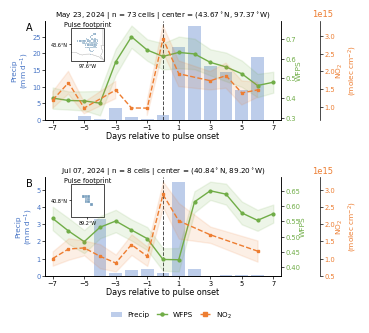

Saved.


In [33]:
# imports needed for footprint inset
from matplotlib.patches import Rectangle, Patch
from matplotlib.collections import PatchCollection
from matplotlib.lines import Line2D

#stuff
EXEMPLAR_EVENTS = [733, 1674]
WINDOW_DAYS = 7
pulse_df = groups_df.copy()

# ── Validate ──────────────────────────────────────────────────────────────────
EXEMPLAR_EVENTS = [e for e in EXEMPLAR_EVENTS if e in pulse_df["group_id"].unique()]
assert len(EXEMPLAR_EVENTS) > 0

n_events = len(EXEMPLAR_EVENTS)
panel_labels = list("ABCDEFGHIJKLMNOPQRSTUVWXYZ")

# ── Figure — PNAS one-column width ────────────────────────────────────────────
cm = 1 / 2.54
fig_w = 8.7 * cm
fig_h = 4.15 * cm * n_events

fig = plt.figure(figsize=(fig_w, fig_h))
outer = gridspec.GridSpec(n_events, 1, hspace=0.58, top=0.96, bottom=0.18, left=0.13, right=0.82)

shared_handles = None
ts_axes = []

for row, eid in enumerate(EXEMPLAR_EVENTS):

    event_pulses = pulse_df[pulse_df["group_id"] == eid].copy()
    event_cells = event_pulses[["grid_lat", "grid_lon"]].drop_duplicates()

    if event_pulses.empty:
        continue

    t0 = event_pulses["datetime"].min()

    # pulse center coordinates
    center_lat = event_cells["grid_lat"].mean()
    center_lon = event_cells["grid_lon"].mean()

    # Soil texture
    soil_str = ""

    if "dominant_texture" in event_pulses.columns:
        es = event_pulses[["grid_lat", "grid_lon", "dominant_texture"]].drop_duplicates(subset=["grid_lat", "grid_lon"]).dropna(subset=["dominant_texture"])

        if len(es) > 0:
            vc = es["dominant_texture"].value_counts()
            soil_str = f"{vc.index[0]} ({vc.iloc[0] / vc.sum():.0%})"

    sm_label = event_pulses["sm_class"].iloc[0] if "sm_class" in event_pulses.columns else ""

    # ±7-day daily window
    sub = df.merge(event_cells, on=["grid_lat", "grid_lon"], how="inner").copy()
    sub = sub[(sub["datetime"] >= t0 - pd.Timedelta(days=WINDOW_DAYS)) & (sub["datetime"] <= t0 + pd.Timedelta(days=WINDOW_DAYS))].copy()
    sub["lag_day"] = np.floor((sub["datetime"] - t0).dt.total_seconds() / 86400.0).astype(int)

    agg_cell = {"precip": ("h_precip_mm", "sum"), "no2": ("no2_mean", "mean")}

    if "WFPS_c" in sub.columns:
        agg_cell["wfps"] = ("WFPS_c", "mean")

    cell_daily = sub.groupby(["grid_lat", "grid_lon", "lag_day"]).agg(**agg_cell).reset_index()

    agg_event = {"precip_mean": ("precip", "mean"), "precip_std": ("precip", "std"), "no2_mean": ("no2", "mean"), "no2_std": ("no2", "std")}

    if "wfps" in cell_daily.columns:
        agg_event["wfps_mean"] = ("wfps", "mean")
        agg_event["wfps_std"] = ("wfps", "std")

    event_daily = cell_daily.groupby("lag_day").agg(**agg_event).reset_index()
    full_lags = pd.DataFrame({"lag_day": np.arange(-WINDOW_DAYS, WINDOW_DAYS + 1)})
    event_daily = full_lags.merge(event_daily, on="lag_day", how="left")
    event_daily[["precip_mean", "precip_std"]] = event_daily[["precip_mean", "precip_std"]].fillna(0)

    # ── TIME SERIES MAIN PANEL ────────────────────────────────────────────────
    ax_ts = fig.add_subplot(outer[row])
    ts_axes.append(ax_ts)

    ax_ts.bar(event_daily["lag_day"], event_daily["precip_mean"], color="#4472C4", alpha=0.35, width=0.8, zorder=2)
    ax_ts.set_ylabel("Precip\n(mm d$^{-1}$)", color="#4472C4", labelpad=1, fontsize=5.3)
    ax_ts.tick_params(axis="y", labelcolor="#4472C4", labelsize=4.8, pad=1, length=2)
    ax_ts.tick_params(axis="x", labelsize=4.8, pad=1, length=2)
    ax_ts.axvline(0, color="black", linestyle="--", linewidth=0.7, alpha=0.7, zorder=3)
    ax_ts.spines[["top"]].set_visible(False)
    ax_ts.set_xlim(-WINDOW_DAYS - 0.5, WINDOW_DAYS + 0.5)
    ax_ts.set_xticks(np.arange(-WINDOW_DAYS, WINDOW_DAYS + 1, 2))
    ax_ts.set_xlabel("Days relative to pulse onset", fontsize=5.8, labelpad=1)

    has_wfps = "wfps_mean" in event_daily.columns

    if has_wfps:
        ax_wfps = ax_ts.twinx()
        vm = event_daily["wfps_mean"].notna()
        ax_wfps.plot(event_daily.loc[vm, "lag_day"], event_daily.loc[vm, "wfps_mean"], color="#70AD47", linewidth=1.0, marker="o", markersize=2.0, label="WFPS", zorder=4)
        ax_wfps.fill_between(event_daily.loc[vm, "lag_day"], (event_daily["wfps_mean"] - event_daily["wfps_std"]).loc[vm], (event_daily["wfps_mean"] + event_daily["wfps_std"]).loc[vm], color="#70AD47", alpha=0.12)
        ax_wfps.set_ylabel("WFPS", color="#70AD47", labelpad=0, fontsize=5.3)
        ax_wfps.tick_params(axis="y", labelcolor="#70AD47", labelsize=4.8, pad=1, length=2)
        ax_wfps.spines[["top"]].set_visible(False)

    ax_no2 = ax_ts.twinx()

    if has_wfps:
        ax_no2.spines["right"].set_position(("outward", 28))

    vn = event_daily["no2_mean"].notna()
    ax_no2.plot(event_daily.loc[vn, "lag_day"], event_daily.loc[vn, "no2_mean"], color="#ED7D31", linestyle="--", linewidth=1.0, marker="s", markersize=2.0, label="NO$_2$", zorder=5)
    ax_no2.fill_between(event_daily.loc[vn, "lag_day"], (event_daily["no2_mean"] - event_daily["no2_std"]).loc[vn], (event_daily["no2_mean"] + event_daily["no2_std"]).loc[vn], color="#ED7D31", alpha=0.12)
    ax_no2.set_ylabel("NO$_2$\n(molec cm$^{-2}$)", color="#ED7D31", labelpad=0, fontsize=5.3)
    ax_no2.tick_params(axis="y", labelcolor="#ED7D31", labelsize=4.8, pad=1, length=2)
    ax_no2.spines[["top"]].set_visible(False)

    # move NO2 scientific notation over outer right axis
    ax_no2.yaxis.get_offset_text().set_x(1.22)
    ax_no2.yaxis.get_offset_text().set_y(1.02)
    ax_no2.yaxis.get_offset_text().set_color("#ED7D31")

    # title with center coordinates instead of sm/soil info
    ax_ts.set_title(f"{t0:%b %d, %Y} | n = {len(event_cells)} cells | center = ({center_lat:.2f}$^\\circ$N, {abs(center_lon):.2f}$^\\circ$W)", fontsize=5.2, pad=2)

    # shared legend handles, only created once
    if shared_handles is None:
        shared_handles = [Patch(facecolor="#4472C4", alpha=0.35, label="Precip")]
        if has_wfps:
            shared_handles.append(Line2D([0], [0], color="#70AD47", linewidth=1.0, marker="o", markersize=2.2, label="WFPS"))
        shared_handles.append(Line2D([0], [0], color="#ED7D31", linestyle="--", linewidth=1.0, marker="s", markersize=2.2, label="NO$_2$"))

    # ── MAP INSET ─────────────────────────────────────────────────────────────
    ax_map = ax_ts.inset_axes([0.05, 0.60, 0.26, 0.33], projection=ccrs.PlateCarree())

    lon_min = event_cells["grid_lon"].min() - 0.45
    lon_max = event_cells["grid_lon"].max() + 0.45
    lat_min = event_cells["grid_lat"].min() - 0.45
    lat_max = event_cells["grid_lat"].max() + 0.45

    ax_map.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())
    ax_map.add_feature(cfeature.LAND.with_scale("50m"), facecolor="white", zorder=1)
    ax_map.add_feature(cfeature.STATES.with_scale("50m"), edgecolor="silver", linewidth=0.25, zorder=2)
    ax_map.add_feature(cfeature.BORDERS.with_scale("50m"), edgecolor="black", linewidth=0.3, zorder=3)
    ax_map.coastlines(resolution="50m", linewidth=0.25, zorder=4)

    footprint_cell_w = 0.1
    footprint_cell_h = 0.1
    rects = []

    for lon, lat in zip(event_cells["grid_lon"], event_cells["grid_lat"]):
        rects.append(Rectangle((lon - footprint_cell_w / 2, lat - footprint_cell_h / 2), footprint_cell_w, footprint_cell_h))

    pc = PatchCollection(rects, facecolor="#6E97B8", edgecolor="white", alpha=0.95, linewidth=0.2, zorder=5)
    pc.set_transform(ccrs.PlateCarree())
    ax_map.add_collection(pc)

    # one tick at midpoint of each inset axis
    xticks = [np.round(0.5 * (lon_min + lon_max), 1)]
    yticks = [np.round(0.5 * (lat_min + lat_max), 1)]

    ax_map.set_xticks(xticks, crs=ccrs.PlateCarree())
    ax_map.set_yticks(yticks, crs=ccrs.PlateCarree())
    ax_map.xaxis.set_major_formatter(cticker.LongitudeFormatter())
    ax_map.yaxis.set_major_formatter(cticker.LatitudeFormatter())
    ax_map.tick_params(labelsize=3.5, pad=1, length=1.4)

    ax_map.set_title("Pulse footprint", fontsize=4.6, pad=1)

# ── Panel labels outside axes ─────────────────────────────────────────────────
fig.canvas.draw()

for ax, label in zip(ts_axes, panel_labels[:len(ts_axes)]):
    pos = ax.get_position()
    fig.text(pos.x0 - 0.055, pos.y1 - 0.005, label, ha="left", va="top", fontsize=7)

# ── One shared legend at bottom ───────────────────────────────────────────────
if shared_handles is not None:
    fig.legend(handles=shared_handles, loc="lower center", bbox_to_anchor=(0.50, 0.025), ncol=len(shared_handles), frameon=False, fontsize=5.2, handlelength=1.4, columnspacing=1.0)

# ── Save ──────────────────────────────────────────────────────────────────────
fig.savefig("/global/home/users/toireasamarie/FINAL Paper Workflow/Paper Figures/exemplar_events_PNAS.pdf", dpi=600, bbox_inches="tight", pad_inches=0.03)
fig.savefig("/global/home/users/toireasamarie/FINAL Paper Workflow/Paper Figures/exemplar_events_PNAS.png", dpi=300, bbox_inches="tight", pad_inches=0.03)
plt.show()

print("Saved.")

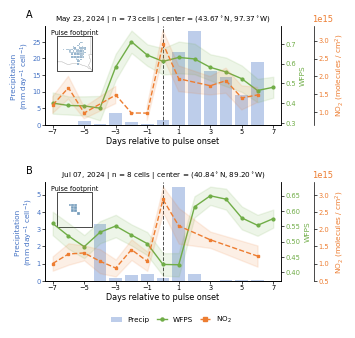

Saved.


In [55]:
# imports needed for footprint inset
from matplotlib.patches import Rectangle, Patch
from matplotlib.collections import PatchCollection
from matplotlib.lines import Line2D

#stuff
EXEMPLAR_EVENTS = [733, 1674]
WINDOW_DAYS = 7
pulse_df = groups_df.copy()

# ── Validate ──────────────────────────────────────────────────────────────────
EXEMPLAR_EVENTS = [e for e in EXEMPLAR_EVENTS if e in pulse_df["group_id"].unique()]
assert len(EXEMPLAR_EVENTS) > 0

n_events = len(EXEMPLAR_EVENTS)
panel_labels = list("ABCDEFGHIJKLMNOPQRSTUVWXYZ")

# ── Figure — PNAS one-column width ────────────────────────────────────────────
cm = 1 / 2.54
fig_w = 8.7 * cm
fig_h = 4.15 * cm * n_events

fig = plt.figure(figsize=(fig_w, fig_h))
outer = gridspec.GridSpec(n_events, 1, hspace=0.58, top=0.96, bottom=0.18, left=0.13, right=0.82)

shared_handles = None
ts_axes = []

for row, eid in enumerate(EXEMPLAR_EVENTS):

    event_pulses = pulse_df[pulse_df["group_id"] == eid].copy()
    event_cells = event_pulses[["grid_lat", "grid_lon"]].drop_duplicates()

    if event_pulses.empty:
        continue

    t0 = event_pulses["datetime"].min()

    # pulse center coordinates
    center_lat = event_cells["grid_lat"].mean()
    center_lon = event_cells["grid_lon"].mean()

    # ±7-day daily window
    sub = df.merge(event_cells, on=["grid_lat", "grid_lon"], how="inner").copy()
    sub = sub[(sub["datetime"] >= t0 - pd.Timedelta(days=WINDOW_DAYS)) & (sub["datetime"] <= t0 + pd.Timedelta(days=WINDOW_DAYS))].copy()
    sub["lag_day"] = np.floor((sub["datetime"] - t0).dt.total_seconds() / 86400.0).astype(int)

    agg_cell = {"precip": ("h_precip_mm", "sum"), "no2": ("no2_mean", "mean")}

    if "WFPS_c" in sub.columns:
        agg_cell["wfps"] = ("WFPS_c", "mean")

    cell_daily = sub.groupby(["grid_lat", "grid_lon", "lag_day"]).agg(**agg_cell).reset_index()

    agg_event = {"precip_mean": ("precip", "mean"), "precip_std": ("precip", "std"), "no2_mean": ("no2", "mean"), "no2_std": ("no2", "std")}

    if "wfps" in cell_daily.columns:
        agg_event["wfps_mean"] = ("wfps", "mean")
        agg_event["wfps_std"] = ("wfps", "std")

    event_daily = cell_daily.groupby("lag_day").agg(**agg_event).reset_index()
    full_lags = pd.DataFrame({"lag_day": np.arange(-WINDOW_DAYS, WINDOW_DAYS + 1)})
    event_daily = full_lags.merge(event_daily, on="lag_day", how="left")
    event_daily[["precip_mean", "precip_std"]] = event_daily[["precip_mean", "precip_std"]].fillna(0)

    # ── TIME SERIES MAIN PANEL ────────────────────────────────────────────────
    ax_ts = fig.add_subplot(outer[row])
    ts_axes.append(ax_ts)

    ax_ts.bar(event_daily["lag_day"], event_daily["precip_mean"], color="#4472C4", alpha=0.35, width=0.8, zorder=2)
    ax_ts.set_ylabel("Precipitation \n(mm day$^{-1}$ cell$^{-1}$)", color="#4472C4", labelpad=1, fontsize=5.3)
    ax_ts.tick_params(axis="y", labelcolor="#4472C4", labelsize=4.8, pad=1, length=2)
    ax_ts.tick_params(axis="x", labelsize=4.8, pad=1, length=2)
    ax_ts.axvline(0, color="black", linestyle="--", linewidth=0.7, alpha=0.7, zorder=3)
    ax_ts.spines[["top"]].set_visible(False)
    ax_ts.set_xlim(-WINDOW_DAYS - 0.5, WINDOW_DAYS + 0.5)
    ax_ts.set_xticks(np.arange(-WINDOW_DAYS, WINDOW_DAYS + 1, 2))
    ax_ts.set_xlabel("Days relative to pulse onset", fontsize=5.8, labelpad=1)

    has_wfps = "wfps_mean" in event_daily.columns

    if has_wfps:
        ax_wfps = ax_ts.twinx()
        vm = event_daily["wfps_mean"].notna()
        ax_wfps.plot(event_daily.loc[vm, "lag_day"], event_daily.loc[vm, "wfps_mean"], color="#70AD47", linewidth=1.0, marker="o", markersize=2.0, label="WFPS", zorder=4)
        ax_wfps.fill_between(event_daily.loc[vm, "lag_day"], (event_daily["wfps_mean"] - event_daily["wfps_std"]).loc[vm], (event_daily["wfps_mean"] + event_daily["wfps_std"]).loc[vm], color="#70AD47", alpha=0.12)
        ax_wfps.set_ylabel("WFPS", color="#70AD47", labelpad=3, fontsize=5.3)
        ax_wfps.tick_params(axis="y", labelcolor="#70AD47", labelsize=4.8, pad=1, length=2)
        ax_wfps.spines[["top"]].set_visible(False)

    ax_no2 = ax_ts.twinx()

    if has_wfps:
        ax_no2.spines["right"].set_position(("outward", 24))

    vn = event_daily["no2_mean"].notna()
    ax_no2.plot(event_daily.loc[vn, "lag_day"], event_daily.loc[vn, "no2_mean"], color="#ED7D31", linestyle="--", linewidth=1.0, marker="s", markersize=2.0, label="NO$_2$", zorder=5)
    ax_no2.fill_between(event_daily.loc[vn, "lag_day"], (event_daily["no2_mean"] - event_daily["no2_std"]).loc[vn], (event_daily["no2_mean"] + event_daily["no2_std"]).loc[vn], color="#ED7D31", alpha=0.12)
    ax_no2.set_ylabel("NO$_2$ (molecules / cm$^{2}$)", color="#ED7D31", labelpad=3, fontsize=5.3)
    ax_no2.tick_params(axis="y", labelcolor="#ED7D31", labelsize=4.8, pad=1, length=2)
    ax_no2.spines[["top"]].set_visible(False)

    # move NO2 scientific notation over outer right axis
    ax_no2.yaxis.get_offset_text().set_x(1.22)
    ax_no2.yaxis.get_offset_text().set_y(1.02)
    ax_no2.yaxis.get_offset_text().set_color("#ED7D31")

    # title with center coordinates
    ax_ts.set_title(f"{t0:%b %d, %Y} | n = {len(event_cells)} cells | center = ({center_lat:.2f}$^\\circ$N, {abs(center_lon):.2f}$^\\circ$W)", fontsize=5.2, pad=2)

    # shared legend handles, only created once
    if shared_handles is None:
        shared_handles = [Patch(facecolor="#4472C4", alpha=0.35, label="Precip")]
        if has_wfps:
            shared_handles.append(Line2D([0], [0], color="#70AD47", linewidth=1.0, marker="o", markersize=2.2, label="WFPS"))
        shared_handles.append(Line2D([0], [0], color="#ED7D31", linestyle="--", linewidth=1.0, marker="s", markersize=2.2, label="NO$_2$"))

    # ── MAP INSET ─────────────────────────────────────────────────────────────
    ax_map = ax_ts.inset_axes([-0.05, 0.55, 0.35, 0.35], projection=ccrs.PlateCarree())

    lon_min = event_cells["grid_lon"].min() - 0.45
    lon_max = event_cells["grid_lon"].max() + 0.45
    lat_min = event_cells["grid_lat"].min() - 0.45
    lat_max = event_cells["grid_lat"].max() + 0.45

    ax_map.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())
    ax_map.add_feature(cfeature.LAND.with_scale("50m"), facecolor="white", zorder=1)
    ax_map.add_feature(cfeature.STATES.with_scale("50m"), edgecolor="silver", linewidth=0.25, zorder=2)
    ax_map.add_feature(cfeature.BORDERS.with_scale("50m"), edgecolor="black", linewidth=0.3, zorder=3)
    ax_map.coastlines(resolution="50m", linewidth=0.25, zorder=4)

    footprint_cell_w = 0.1
    footprint_cell_h = 0.1
    rects = []

    for lon, lat in zip(event_cells["grid_lon"], event_cells["grid_lat"]):
        rects.append(Rectangle((lon - footprint_cell_w / 2, lat - footprint_cell_h / 2), footprint_cell_w, footprint_cell_h))

    pc = PatchCollection(rects, facecolor="#6E97B8", edgecolor="white", alpha=0.95, linewidth=0.2, zorder=5)
    pc.set_transform(ccrs.PlateCarree())
    ax_map.add_collection(pc)

    # remove inset map ticks and tick labels
    ax_map.set_xticks([])
    ax_map.set_yticks([])

    ax_map.set_title("Pulse footprint", fontsize=4.6, pad=1)

# ── Panel labels outside axes ─────────────────────────────────────────────────
fig.canvas.draw()

for ax, label in zip(ts_axes, panel_labels[:len(ts_axes)]):
    pos = ax.get_position()
    fig.text(pos.x0 - 0.055, pos.y1 + 0.05, label, ha="left", va="top", fontsize=7)

# ── One shared legend at bottom ───────────────────────────────────────────────
if shared_handles is not None:
    fig.legend(handles=shared_handles, loc="lower center", bbox_to_anchor=(0.50, 0.025), ncol=len(shared_handles), frameon=False, fontsize=5.2, handlelength=1.4, columnspacing=1.0)

# ── Save ──────────────────────────────────────────────────────────────────────
fig.savefig("/global/home/users/toireasamarie/FINAL Paper Workflow/Paper Figures/exemplar_events_PNAS.pdf", dpi=600, bbox_inches="tight", pad_inches=0.03)
fig.savefig("/global/home/users/toireasamarie/FINAL Paper Workflow/Paper Figures/exemplar_events_PNAS.png", dpi=300, bbox_inches="tight", pad_inches=0.03)
plt.show()

print("Saved.")